# Statistical Assurance Regions: SciGuard reproducibility workflow
**Canonical notebook:** `SciGuard_JMLR_Reproducible_Analysis_MIMIC_IV_Clean.ipynb`  
**Results revision:** October 20, 2026 (Section 13) | **Plotting cleanup:** October 12, 2026 | **Major revision:** September 27, 2026 | Faustus Domebale Maale and Hui Yi

This notebook is the single current workflow. It contains the inferential calibration,
nested model refits, corrected missingness mechanisms, WDBC stress test, sample-size /
dependence / grid / bootstrap ablations, continuous extension, pilot-design example,
credentialed MIMIC-IV execution path, and the results-revision analyses (validity
anatomy, risk-margin power and exact planning, tolerance-certification profiles, and the
effective sample size of the MIMIC false-negative specification). All statistical functions are imported from
`src/sciguard`; none are redefined later in the notebook.

**Evidence status:** synthetic and WDBC analyses are reproducible using the bundled data.
Credentialed MIMIC-IV results were supplied in the Revision 4 project; local re-execution requires separately obtained data. A successful synthetic loader
test does not constitute clinical benchmark evidence. The revision is an applied-methods
framework, not a claim of a new Gaussian-bootstrap theorem or clinical safety.

## 1. Run controls and reproducibility
Unzip the entire package and open this notebook from its root. Install with
`python -m pip install -e ".[experiments,notebook]"`. Restart the kernel and run all cells.

`SCIGUARD_PROFILE=full` (default) recomputes every public/synthetic section. Use
`SCIGUARD_PROFILE=smoke` for a short execution check; smoke results have their own directory
and are never exported to manuscript tables. Full runs use 500 calibration replications,
200 nested refits, 100 missingness refits, 20,000 independent reference rows per refit,
2,000 bootstrap draws (5,000 for WDBC), and a fixed seed. Training is single-threaded
for reproducibility. Runtime depends on hardware.

Original notebooks and results are retained under `archive/pre_revision/` and are never
silently loaded by this workflow. The root notebook's displayed outputs are from its
recorded execution; rerunning replaces them with current outputs.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'src/sciguard/experiments.py').is_file()
             and (p / 'data/simulation_true_risks.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook inside the unzipped SciGuard_JMLR_Target folder.')
sys.path.insert(0, str(ROOT / 'src'))
import sciguard
from sciguard.experiments import AnalysisRun, RunConfig, SECTIONS, LABELS
from sciguard import certify, certify_overlapping_groups, continuous_upper_envelope
from sciguard.plotting import (schematic, calibration_figure, sensitivity_figure,
    nested_figure, missingness_figure, wdbc_figure, continuous_figure, stress_figure)

PROFILE = os.environ.get('SCIGUARD_PROFILE', 'full')
if PROFILE not in {'full', 'smoke'}:
    raise ValueError('SCIGUARD_PROFILE must be full or smoke')
CONFIG = RunConfig() if PROFILE == 'full' else RunConfig.smoke()
THREAD_LIMIT = threadpool_limits(limits=1)
run = AnalysisRun(ROOT, CONFIG)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('SciGuard', sciguard.__version__, '| profile:', PROFILE)
display(pd.DataFrame([run.manifest['config']]).T.rename(columns={0: 'Value'}))

SciGuard 0.2.0 | profile: full


,Value
profile,full
seed,20260927
alpha,0.05
tau_calibration,0.34
tau_nested,0.35
calibration_reps,500
sensitivity_reps,300
continuous_reps,200
nested_reps,200
missingness_reps,100


### Figure styles and uncertainty
Method colors are fixed across all figures. Models use hatching; decision maps use green/yellow/salmon/gray for certification states. These are distinct color semantics.

Coverage and point-reference containment show **pointwise 95% Wilson intervals across independent simulation replications**. Mean ARR uses **approximate pointwise 95% t intervals** (sensitivity uses the existing normal approximation, mean ± 1.96 MCSE). These quantify Monte Carlo uncertainty and are not simultaneous over all plotted comparisons. Finite-reference uncertainty is separate and is shown as a range, not mislabeled as a confidence interval. At degenerate all-zero/all-one results, a mean interval can collapse and should not be interpreted as proof of zero uncertainty.

WDBC/MIMIC decision maps use existing **one-sided simultaneous upper confidence bounds**; they do not need invented two-sided intervals. Additional clinical risk plots display those bounds explicitly. Continuous contours show one illustrative replication and its Lipschitz upper envelope; the analytic true risk has no estimation CI. Multiplier validity is asymptotic.

Stale outputs were cleared. Run all cells to regenerate figures and tables from your local project; MIMIC is opt-in.

In [3]:
# Shared styles: method colors denote inference procedures; region colors denote decisions.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy.stats import t as student_t
from sciguard.metrics import wilson_interval
import sciguard.plotting as plotting

COLORS = {
    'pointwise': '#ADB5BD', 'normal_bonferroni': '#E8B77A',
    'multiplier': '#79B7B4', 'exact_bonferroni': '#8CA9CF',
    'hoeffding': '#B5A0CA', 'holm': '#99BE9C',
}
REGION_COLORS = {'safe': '#66C2A5', 'borderline': '#FEE08B',
                 'uncertified': '#F28E8C', 'insufficient': '#D5D8DC',
                 'failure': '#B5A0CA'}
TARGET_COLOR, REFERENCE_COLOR, HEADER_COLOR = '#A43138', '#303840', '#1F4E79'
plotting.COLORS.update(COLORS)
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 11,
    'axes.labelsize': 10, 'legend.fontsize': 8.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'savefig.facecolor': 'white',
    'pdf.fonttype': 42, 'ps.fonttype': 42})


def mean_ci(values):
    """Approximate pointwise 95% t interval for a mean across independent replications."""
    v = np.asarray(values, float)
    v = v[np.isfinite(v)]
    if len(v) < 2:
        return (float(v[0]), np.nan, np.nan) if len(v) else (np.nan,)*3
    mean = v.mean()
    half = student_t.ppf(.975, len(v)-1) * v.std(ddof=1)/np.sqrt(len(v))
    return mean, max(0., mean-half), min(1., mean+half)


def style_axis(ax):
    ax.grid(axis='y', alpha=.2, linewidth=.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)


def finish_figure(fig, name, directory=None):
    directory = Path(directory) if directory is not None else run.fig
    directory.mkdir(parents=True, exist_ok=True)
    for ext in ('png', 'pdf'):
        fig.savefig(directory / f'{name}.{ext}', dpi=300, bbox_inches='tight')
    display(fig)
    plt.close(fig)


def risk_bound_figure(data, risk_col, upper_col, domain_col, name, directory,
                      tolerance, eligibility_col='eligible'):
    """Observed risks and existing one-sided simultaneous upper confidence bounds."""
    d = data.loc[data['method'].eq('exact_bonferroni')].copy()
    domains = sorted(d[domain_col].unique())
    models = list(dict.fromkeys(d.Model))
    finite_upper = pd.to_numeric(d[upper_col], errors='coerce').dropna()
    ymax = min(1.03, max(tolerance, finite_upper.max() if len(finite_upper) else tolerance)*1.15 + .015)
    domain_label = 'shift level' if domain_col == 'Shift' else 'temporal domain'
    fig, axes = plt.subplots(1, len(models), figsize=(4*len(models), 4.8),
                             squeeze=False, sharey=True, layout='constrained')
    for ax, model in zip(axes[0], models):
        for i, domain in enumerate(domains):
            s = d.loc[(d.Model == model) & (d[domain_col] == domain)].sort_values('Missingness')
            s = s.loc[s[eligibility_col].astype(bool)]
            if s.empty:
                continue
            ax.plot(s.Missingness, s[risk_col], marker='o', markersize=4,
                    color=COLORS['exact_bonferroni'], alpha=.85, linestyle=['-','--',':','-.'][i%4])
            ax.vlines(s.Missingness, s[risk_col], s[upper_col],
                      color=COLORS['exact_bonferroni'], alpha=.65, linewidth=1)
            ax.plot(s.Missingness, s[upper_col], linestyle='--', marker='_',
                    color=COLORS['exact_bonferroni'], alpha=.65)
        ax.axhline(tolerance, color=TARGET_COLOR, linestyle=':', linewidth=1.3)
        ax.set(title=model, xlabel='Added MCAR missingness', ylim=(0, ymax))
        style_axis(ax)
    axes[0, 0].set_ylabel('Observed risk / simultaneous upper bound')
    fig.suptitle('Exact Bonferroni: one-sided 95% familywise upper bounds')
    fig.legend(handles=[Line2D([0],[0],color=COLORS['exact_bonferroni'],marker='o',
                 label=f'Observed risk (each curve is one {domain_label})'),
         Line2D([0],[0],color=COLORS['exact_bonferroni'],linestyle='--',
                 label='Simultaneous upper confidence bound'),
         Line2D([0],[0],color=TARGET_COLOR,linestyle=':',label='Risk tolerance')],
         loc='outside lower center', ncol=1, frameon=False)
    finish_figure(fig, name, directory)


## 2. Target, assumptions, and guarantees
Condition on the training/design data and a frozen pipeline $g$. For a prespecified
environment $e$, write $R_g(e)=E[L_e]$, $0\leq L_e\leq1$, and
$\mathcal A_\tau=\{e:R_g(e)\leq\tau\}$. A simultaneous band $U_e$ yields the inner estimate
$\widehat{\mathcal A}_\tau=\{e:U_e\leq\tau\}$.

The fundamental event is **simultaneous risk coverage**, not only containment at one
tolerance. If every $R_e\leq U_e$, then containment holds for **every** tolerance at once.
Thus inspecting several tolerances on the same fixed band does not invalidate this event.
Operational tolerances should nevertheless be prospectively justified. Changing the loss,
model, environment family, or certification method after seeing assurance outcomes needs
independent data or multiplicity control. Exact Holm here is a test at a fixed tolerance,
not a confidence band constructed uniformly over tolerances.

| Method | Scope |
|---|---|
| Multiplier | Asymptotic simultaneous band; requires appropriate row independence, nondegenerate population variances, and an adequate Gaussian approximation. Finite bootstrap draws add Monte Carlo error. |
| Normal Bonferroni | Multiplicity-corrected normal approximation; not finite-sample exact. |
| Exact Bonferroni | One-sided Clopper-Pearson bounds at $\alpha/K$ for binary losses; finite-sample familywise control. |
| Hoeffding | $\min(1,\widehat R_k+\sqrt{\log(K/\alpha)/(2n_k)})$; finite-sample control for independent bounded observations. |
| Exact Holm | Binomial lower-tail tests of $H_{0k}:R_k\geq\tau$, adjusted by Holm; finite-sample containment at a fixed tolerance. |
| Pointwise normal | Diagnostic comparator only; no familywise guarantee. |

For the multiplier route, zero empirical variance produces upper bound 1, never a false
zero-risk certificate. Exact binomial bounds can still certify a zero-error column if the
sample is sufficiently large. All moments use `ddof=0` consistently.

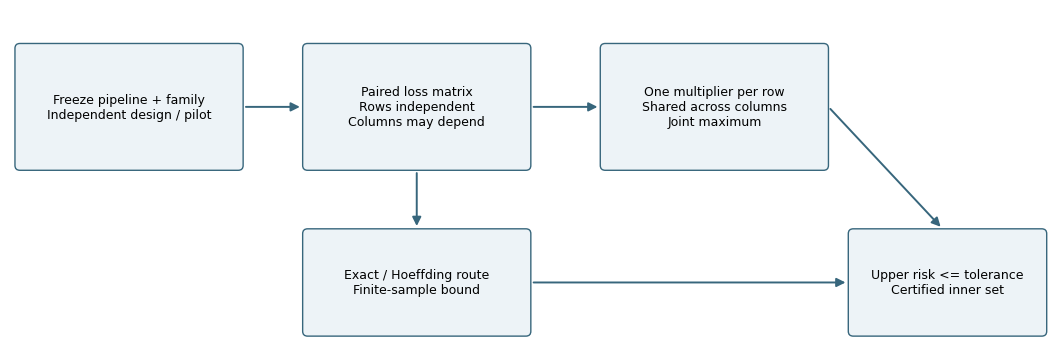

,Multiplier upper,Exact binomial upper
0,1.0,0.045007
1,1.0,0.045007
2,1.0,0.045007
3,1.0,0.045007
4,1.0,0.045007


In [5]:
fig = schematic(run)
display(fig); plt.close(fig)
toy_losses = np.zeros((100, 5))
display(pd.DataFrame({
    'Multiplier upper': certify(toy_losses, .10, n_boot=200, rng=1).upper,
    'Exact binomial upper': certify(toy_losses, .10, method='exact_bonferroni').upper
}))

### 2.1 Why shared transformations do not violate row independence
Let $Z_i$ be independent source observations and $V_i$ independent row-specific stress
randomness. With the design fixed, each vector
$\mathbf L_i=(h_1(Z_i,V_i),\ldots,h_K(Z_i,V_i))$ is a measurable function of one independent
row. Therefore the vectors are i.i.d.; their coordinates can be arbitrarily dependent,
including identical columns. One Gaussian multiplier is shared across each row's columns.

This argument fails if transformations normalize using the **assurance batch**, if repeated
patients are treated as independent, or if a shared random nuisance is not conditioned on.
The revised MAR/MNAR generators use fixed population-calibrated intercepts and row-local
randomness. The conditional-covariance sampler draws from the same Gaussian law as direct
row multipliers; this computational equivalence does not make the inferential approximation exact.

### 2.2 Evaluation metrics
With known truth: simultaneous coverage, containment, ARR (fraction of safe environments
certified), and UCP (unsafe fraction among certified environments). UCP is zero for an empty
certified set; ARR is undefined (`NaN`) if no environment is truly safe. Always report the
certified count so vacuous containment is visible. Confidence intervals for empirical
coverage/containment use Wilson intervals over independent Monte Carlo replications.

## 3. Calibration with exactly known risks
The supplied 25-cell risk surface is a calibration-only design. Correlated Bernoulli losses
are generated through a Gaussian copula; the model-fitting study is separate. Latent Gaussian
correlation is not the same as observed binary-loss correlation. No archived numerical targets
are imposed as assertions, and unfavorable results remain in the output.

,Missingness,Shift,Risk
0,0.0,0.00,0.273033
1,0.0,0.15,0.285337
2,0.0,0.30,0.299393
3,0.0,0.45,0.316880
4,0.0,0.60,0.338590
5,0.1,0.00,0.292153
6,0.1,0.15,0.303140
7,0.1,0.30,0.315823
8,0.1,0.45,0.331613
9,0.1,0.60,0.351550


Running calibration (full)
Completed calibration: 4.0s


,method,replications,simultaneous_coverage,simultaneous_coverage_mcse,simultaneous_coverage_lo,simultaneous_coverage_hi,containment,containment_mcse,containment_lo,containment_hi,ARR,ARR_mcse,UCP,UCP_mcse,n_certified,n_certified_mcse,inference_seconds,inference_seconds_mcse
0,pointwise,500,0.514,0.0224,0.4703,0.5575,0.958,0.009,0.9366,0.9724,0.5221,0.0071,0.0042,0.0009,7.358,0.1037,0.0006,0.0000
1,normal_bonferroni,500,0.938,0.0108,0.9133,0.9560,0.998,0.002,0.9888,0.9996,0.2820,0.0057,0.0002,0.0002,3.950,0.0807,0.0006,0.0000
2,multiplier,500,0.928,0.0116,0.9019,0.9475,0.998,0.002,0.9888,0.9996,0.2973,0.0059,0.0002,0.0002,4.164,0.0829,0.0032,0.0001
3,exact_bonferroni,500,0.960,0.0088,0.9390,0.9740,0.998,0.002,0.9888,0.9996,0.2577,0.0055,0.0002,0.0002,3.610,0.0777,0.0010,0.0001
4,hoeffding,500,1.000,0.0000,0.9924,1.0000,1.000,0.000,0.9924,1.0000,0.1376,0.0043,0.0000,0.0000,1.926,0.0601,0.0003,0.0000
5,holm,500,NaN,NaN,NaN,NaN,0.998,0.002,0.9888,0.9996,0.2696,0.0059,0.0002,0.0002,3.776,0.0826,0.0005,0.0000


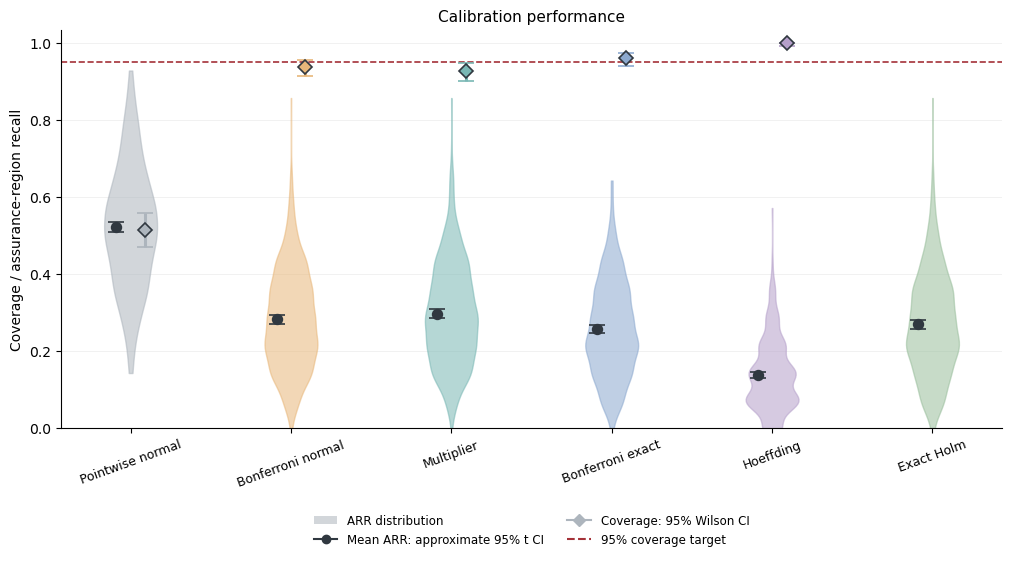

In [15]:
truth = pd.read_csv(ROOT / 'data/simulation_true_risks.csv')
assert len(truth) == 25 and truth.Risk.between(0, 1).all()
display(truth)
calibration_replications, calibration_summary = run.section('calibration', SECTIONS['calibration'])
display(calibration_summary.round(4))
methods = ['pointwise', 'normal_bonferroni', 'multiplier', 'exact_bonferroni', 'hoeffding', 'holm']
fig, ax = plt.subplots(figsize=(10, 5.5), layout='constrained')
for i, method in enumerate(methods):
    d = calibration_replications.loc[calibration_replications.method == method]
    values = d.ARR.dropna().to_numpy()
    if len(values) > 1 and np.ptp(values) > 0:
        violin = ax.violinplot([values], positions=[i], widths=.33, showextrema=False)
        for body in violin['bodies']:
            body.set_facecolor(COLORS[method]); body.set_edgecolor(COLORS[method]); body.set_alpha(.55)
    mean, lo, hi = mean_ci(values)
    if np.isfinite(lo):
        ax.errorbar(i-.09, mean, yerr=[[mean-lo],[hi-mean]], fmt='o',
                    color=REFERENCE_COLOR, capsize=6, markersize=7, zorder=5,
                   linewidth=2.2, markeredgewidth=1.2)
    if method != 'holm':
        v = d.simultaneous_coverage.dropna()
        estimate = v.mean()
        _, lo, hi = wilson_interval(v.to_numpy())
        ax.errorbar(i+.09, estimate, yerr=[[estimate-lo],[hi-estimate]], fmt='D',
                    color=COLORS[method], markeredgecolor=REFERENCE_COLOR, capsize=6, zorder=5,
                   markersize=7, linewidth=2.2, markeredgewidth=1.2)
ax.axhline(.95, color=TARGET_COLOR, linestyle='--', linewidth=1.2)
ax.set(xticks=range(len(methods)), xticklabels=[LABELS[m] for m in methods],
       ylim=(0,1.035), ylabel='Coverage / assurance-region recall', title='Calibration performance')
ax.tick_params(axis='x', rotation=20, labelsize=9)
style_axis(ax)
ax.legend(handles=[Patch(facecolor='#ADB5BD', alpha=.55, label='ARR distribution'),
    Line2D([0],[0],marker='o',color=REFERENCE_COLOR,label='Mean ARR: approximate 95% t CI'),
    Line2D([0],[0],marker='D',color='#ADB5BD',label='Coverage: 95% Wilson CI'),
    Line2D([0],[0],color=TARGET_COLOR,linestyle='--',label='95% coverage target')],
    loc='upper center',bbox_to_anchor=(.5,-.19),ncol=2,frameon=False)
finish_figure(fig, 'calibration_combined')


## 4. Nested fitted-pipeline experiment
Every replication draws fresh training data, fits logistic regression and histogram gradient
boosting, then uses separate source-calibration, assurance, and reference samples. Models share
the same generated rows and stress randomness for a paired comparison. The protected first
feature and all preprocessing are fixed before assurance. This changes the earlier experiment;
the revised numbers must not be compared as if only the random seed changed.

**Reference uncertainty:** 20,000 reference observations improve on the former 1,500, but their
means are still not exact true risks. Simultaneous two-sided exact binomial intervals use total
reference error 0.01 across both models in each refit. Cells whose intervals cross the tolerance
are ambiguous. `containment_lower` certifies containment only when all selected cells are
reference-confirmed safe; `containment_upper` rules it out only if a selected cell is
reference-confirmed unsafe. These are bounds on a containment indicator on the reference
coverage event, not confidence limits for a population coverage probability. Their averages
are reported alongside point-reference metrics and Wilson intervals. Reference coverage is
per refit, not simultaneous over every refit in the experiment.

Running nested (full)


C:\Users\maale\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\maale\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\maale\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\maale\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\maale\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

  nested refits 25/200
  nested refits 50/200
  nested refits 75/200
  nested refits 100/200
  nested refits 125/200
  nested refits 150/200
  nested refits 175/200
  nested refits 200/200
Completed nested: 942.5s


,Model,method,replications,reference_containment,reference_containment_mcse,reference_containment_lo,reference_containment_hi,containment_lower,containment_lower_mcse,containment_lower_lo,...,reference_UCP,reference_UCP_mcse,reference_n_certified,reference_n_certified_mcse,ambiguous_environments,ambiguous_environments_mcse,reference_halfwidth_max,reference_halfwidth_max_mcse,inference_seconds,inference_seconds_mcse
0,Logistic regression,normal_bonferroni,200,1.0,0.0,0.9812,1.0,0.960,0.0139,0.9231,...,0.0,0.0,2.670,0.2642,1.775,0.1247,0.0121,0.0,0.0008,0.0000
1,Logistic regression,multiplier,200,1.0,0.0,0.9812,1.0,0.940,0.0168,0.8981,...,0.0,0.0,3.785,0.3031,1.775,0.1247,0.0121,0.0,0.0028,0.0000
2,Logistic regression,exact_bonferroni,200,1.0,0.0,0.9812,1.0,0.970,0.0121,0.9361,...,0.0,0.0,2.220,0.2448,1.775,0.1247,0.0121,0.0,0.0010,0.0000
3,Logistic regression,hoeffding,200,1.0,0.0,0.9812,1.0,0.995,0.0050,0.9722,...,0.0,0.0,0.745,0.1510,1.775,0.1247,0.0121,0.0,0.0003,0.0000
4,Logistic regression,holm,200,1.0,0.0,0.9812,1.0,0.955,0.0147,0.9167,...,0.0,0.0,2.670,0.2991,1.775,0.1247,0.0121,0.0,0.0006,0.0000
5,HistGradientBoosting,normal_bonferroni,200,1.0,0.0,0.9812,1.0,1.000,0.0000,0.9812,...,0.0,0.0,10.705,0.2594,0.005,0.0050,0.0119,0.0,0.0008,0.0000
6,HistGradientBoosting,multiplier,200,1.0,0.0,0.9812,1.0,1.000,0.0000,0.9812,...,0.0,0.0,11.765,0.2436,0.005,0.0050,0.0119,0.0,0.0028,0.0001
7,HistGradientBoosting,exact_bonferroni,200,1.0,0.0,0.9812,1.0,1.000,0.0000,0.9812,...,0.0,0.0,10.095,0.2680,0.005,0.0050,0.0119,0.0,0.0010,0.0000
8,HistGradientBoosting,hoeffding,200,1.0,0.0,0.9812,1.0,1.000,0.0000,0.9812,...,0.0,0.0,6.320,0.2892,0.005,0.0050,0.0119,0.0,0.0003,0.0000
9,HistGradientBoosting,holm,200,1.0,0.0,0.9812,1.0,1.000,0.0000,0.9812,...,0.0,0.0,11.710,0.2946,0.005,0.0050,0.0119,0.0,0.0005,0.0000


,Model,replications,fit_seconds,fit_seconds_mcse,nominal_reference_risk,nominal_reference_risk_mcse,reference_safe_fraction,reference_safe_fraction_mcse
0,Logistic regression,200,0.0064,0.0001,0.3144,0.0003,0.9997,0.0003
1,HistGradientBoosting,200,0.1811,0.0025,0.2828,0.0003,1.0000,0.0000


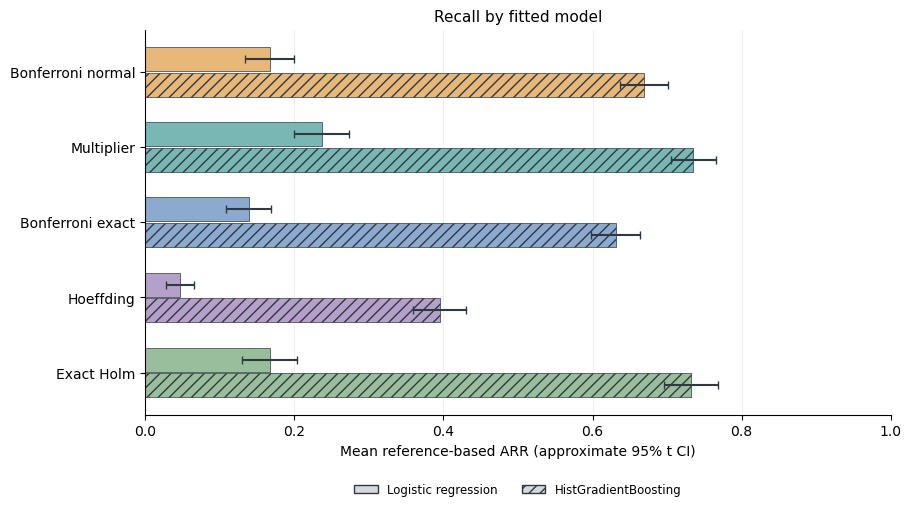

In [9]:
nested_replications, nested_summary = run.section('nested', SECTIONS['nested'])
display(nested_summary.round(4))
display(pd.read_csv(run.out / 'nested_fit_summary.csv').round(4))
methods = ['normal_bonferroni','multiplier','exact_bonferroni','hoeffding','holm']
models = ['Logistic regression','HistGradientBoosting']
fig, ax = plt.subplots(figsize=(9,5),layout='constrained')
for j, model in enumerate(models):
    for i, method in enumerate(methods):
        v = nested_replications.loc[(nested_replications.Model==model) &
                (nested_replications.method==method),'reference_ARR']
        mean, lo, hi = mean_ci(v)
        y = i+(j-.5)*.34
        ax.barh(y,mean,height=.32,color=COLORS[method],hatch='' if j==0 else '///',
                edgecolor=REFERENCE_COLOR,linewidth=.5)
        if np.isfinite(lo):
            ax.errorbar(mean,y,xerr=[[mean-lo],[hi-mean]],fmt='none',
                        ecolor=REFERENCE_COLOR,capsize=3)
ax.set(yticks=range(len(methods)),yticklabels=[LABELS[m] for m in methods],xlim=(0,1),
    xlabel='Mean reference-based ARR (approximate 95% t CI)',title='Recall by fitted model')
ax.invert_yaxis(); ax.grid(axis='x',alpha=.2); ax.set_axisbelow(True)
ax.legend(handles=[Patch(facecolor='#D5D8DC',edgecolor=REFERENCE_COLOR,label=models[0]),
    Patch(facecolor='#D5D8DC',edgecolor=REFERENCE_COLOR,hatch='///',label=models[1])],
    loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2,frameon=False)
finish_figure(fig,'nested_combined')


### 4.1 ATC is evaluated as a performance predictor
Average Thresholded Confidence with maximum-probability scores is calibrated on independent
labeled source data. It uses target confidence scores to predict target risk. We report MAE,
bias, and RMSE against the independent reference estimates. ATC is not placed in a table of
formal certification guarantees. Tied scores use a consistent strict threshold in calibration
and deployment. This is an ATC-MC implementation, not a newly corrected certifier.

In [11]:
display(pd.read_csv(run.out / 'atc_prediction_summary.csv').round(4))

,Model,replications,MAE,MAE_mcse,bias,bias_mcse,RMSE,RMSE_mcse
0,Logistic regression,200,0.0313,0.0016,-0.0123,0.0026,0.0331,0.0016
1,HistGradientBoosting,200,0.0300,0.0013,-0.0143,0.0023,0.0323,0.0013


## 5. Missingness mechanisms
All mechanisms keep feature 0 observed; severity is the missing fraction among the other
nine eligible features. MAR depends only on observed feature 0. MNAR depends on the feature
being hidden. Fixed logistic intercepts are calibrated under the known simulation distribution,
not renormalized on each assurance batch. Structured failure hides features 1-3 together while
maintaining the same marginal severity for all eligible features. The label equation and model
are unchanged across mechanisms, and masks are nested as severity increases.

The reference interval budget is 0.01 across all four mechanisms within each refit. MNAR and
block-failure scenarios are sensitivity assumptions; the results do not identify a real clinical
missingness mechanism. Realized missingness is exported for every environment.

Running missingness (full)
Completed missingness: 83.9s


,Mechanism,method,replications,reference_containment,reference_containment_mcse,reference_containment_lo,reference_containment_hi,containment_lower,containment_lower_mcse,containment_lower_lo,...,containment_upper_lo,containment_upper_hi,reference_ARR,reference_ARR_mcse,reference_UCP,reference_UCP_mcse,ambiguous_environments,ambiguous_environments_mcse,mean_reference_risk,mean_reference_risk_mcse
0,MCAR,multiplier,100,1.0,0.0,0.963,1.0,0.94,0.0239,0.8752,...,0.963,1.0,0.2106,0.0215,0.0,0.0,1.83,0.1741,0.3263,0.0003
1,MCAR,exact_bonferroni,100,1.0,0.0,0.963,1.0,0.99,0.0100,0.9455,...,0.963,1.0,0.1125,0.0149,0.0,0.0,1.83,0.1741,0.3263,0.0003
2,MCAR,holm,100,1.0,0.0,0.963,1.0,0.97,0.0171,0.9155,...,0.963,1.0,0.1350,0.0200,0.0,0.0,1.83,0.1741,0.3263,0.0003
3,MAR,multiplier,100,1.0,0.0,0.963,1.0,0.99,0.0100,0.9455,...,0.963,1.0,0.2488,0.0247,0.0,0.0,0.28,0.0726,0.3236,0.0003
4,MAR,exact_bonferroni,100,1.0,0.0,0.963,1.0,1.00,0.0000,0.9630,...,0.963,1.0,0.1412,0.0183,0.0,0.0,0.28,0.0726,0.3236,0.0003
5,MAR,holm,100,1.0,0.0,0.963,1.0,0.99,0.0100,0.9455,...,0.963,1.0,0.1812,0.0259,0.0,0.0,0.28,0.0726,0.3236,0.0003
6,MNAR,multiplier,100,1.0,0.0,0.963,1.0,1.00,0.0000,0.9630,...,0.963,1.0,0.3031,0.0283,0.0,0.0,0.00,0.0000,0.3210,0.0003
7,MNAR,exact_bonferroni,100,1.0,0.0,0.963,1.0,1.00,0.0000,0.9630,...,0.963,1.0,0.1750,0.0214,0.0,0.0,0.00,0.0000,0.3210,0.0003
8,MNAR,holm,100,1.0,0.0,0.963,1.0,1.00,0.0000,0.9630,...,0.963,1.0,0.2275,0.0291,0.0,0.0,0.00,0.0000,0.3210,0.0003
9,Structured,multiplier,100,1.0,0.0,0.963,1.0,0.93,0.0256,0.8625,...,0.963,1.0,0.2319,0.0236,0.0,0.0,0.98,0.1421,0.3253,0.0003


Missingness,0.0,0.1,0.2,0.3
Mechanism,,,,
MAR,0.0,0.0999,0.1998,0.3001
MCAR,0.0,0.0998,0.1997,0.3000
MNAR,0.0,0.0999,0.1999,0.3000
Structured,0.0,0.1000,0.2003,0.3011


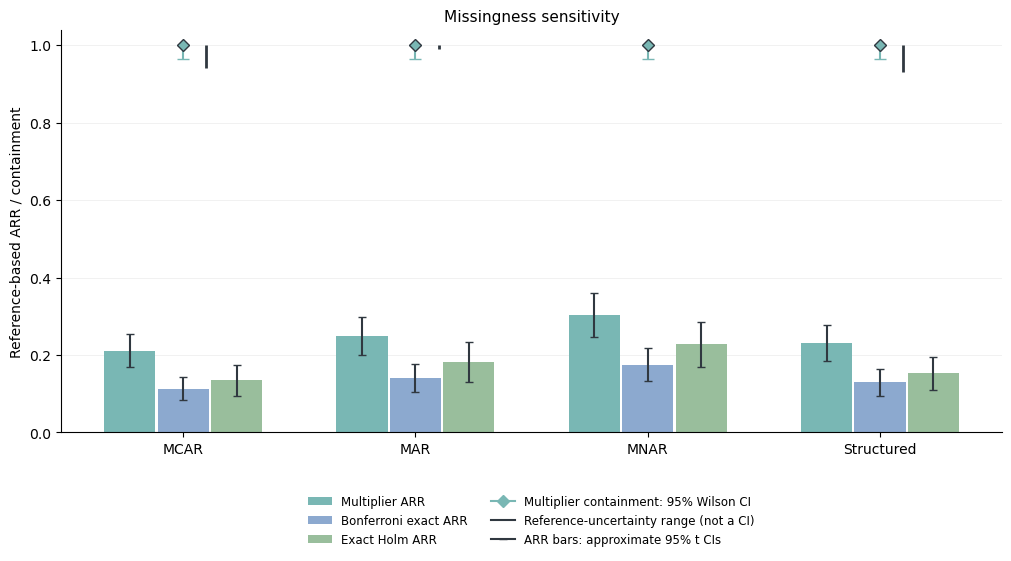

In [17]:
missingness_replications, missingness_summary = run.section('missingness', SECTIONS['missingness'])
display(missingness_summary.round(4))
rates = pd.read_csv(run.out / 'missingness_environment_detail.csv')
display(rates.groupby(['Mechanism','Missingness']).realized_missingness.mean().unstack().round(4))
mechanisms=['MCAR','MAR','MNAR','Structured']
methods=['multiplier','exact_bonferroni','holm']
fig, ax=plt.subplots(figsize=(10,5.5),layout='constrained')
for j,method in enumerate(methods):
    for i,mechanism in enumerate(mechanisms):
        d=missingness_replications.loc[(missingness_replications.method==method)&
                (missingness_replications.Mechanism==mechanism)]
        mean,lo,hi=mean_ci(d.reference_ARR)
        x=i+(j-1)*.23
        ax.bar(x,mean,width=.22,color=COLORS[method],label=LABELS[method]+' ARR' if i==0 else None)
        if np.isfinite(lo):
            ax.errorbar(x,mean,yerr=[[mean-lo],[hi-mean]],fmt='none',ecolor=REFERENCE_COLOR,capsize=3)
        if method=='multiplier':
            v=d.reference_containment.dropna(); estimate=v.mean()
            _,lo,hi=wilson_interval(v.to_numpy())
            ax.errorbar(i,estimate,yerr=[[estimate-lo],[hi-estimate]],fmt='D',
                        color=COLORS[method],markeredgecolor=REFERENCE_COLOR,capsize=4,zorder=5)
            ax.vlines(i+.10,d.containment_lower.mean(),d.containment_upper.mean(),
                      color=REFERENCE_COLOR,linewidth=2,zorder=5)
ax.set(xticks=range(4),xticklabels=mechanisms,ylim=(0,1.04),
       ylabel='Reference-based ARR / containment',title='Missingness sensitivity')
style_axis(ax)
h,l=ax.get_legend_handles_labels()
h.extend([Line2D([0],[0],marker='D',color=COLORS['multiplier'],label='Multiplier containment: 95% Wilson CI'),
          Line2D([0],[0],color=REFERENCE_COLOR,label='Reference-uncertainty range (not a CI)'),
          Line2D([0],[0],color=REFERENCE_COLOR,marker='_',label='ARR bars: approximate 95% t CIs')])
ax.legend(handles=h,loc='upper center',bbox_to_anchor=(.5,-.13),ncol=2,frameon=False)
finish_figure(fig,'missingness_combined')


## 6. WDBC: three frozen models and grid resolution
The 65/35 stratified split (random state 42), train-only imputation/scaling, and shared feature
noise/missingness are applied to logistic regression, Extra Trees, and histogram gradient
boosting. This remains a small **semisynthetic stress test**, not a natural hospital/temporal
shift study. No ground-truth ARR, UCP, or repeated-sampling coverage is inferred from this
single real-data split.

Each model/design is a separate assurance family. Selecting the best model after comparing
these separate bands is not jointly protected. The nonuniform 36-cell primary grid and the
equally spaced 6-by-6 grid contain different missingness values; equal counts do not make
them identical designs. Grid fractions are not continuous areas.

Running wdbc (full)
Completed wdbc: 3.2s


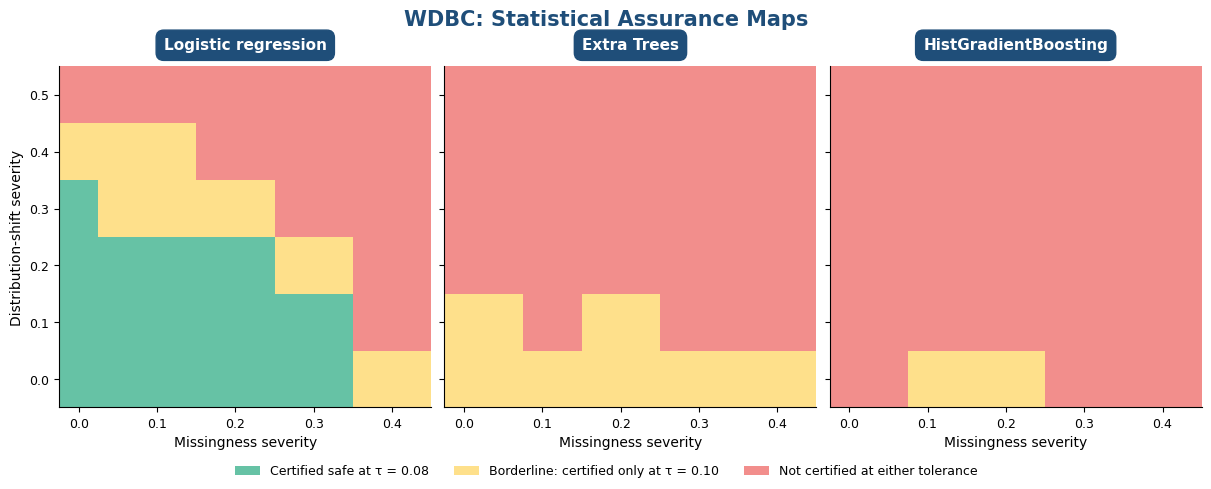

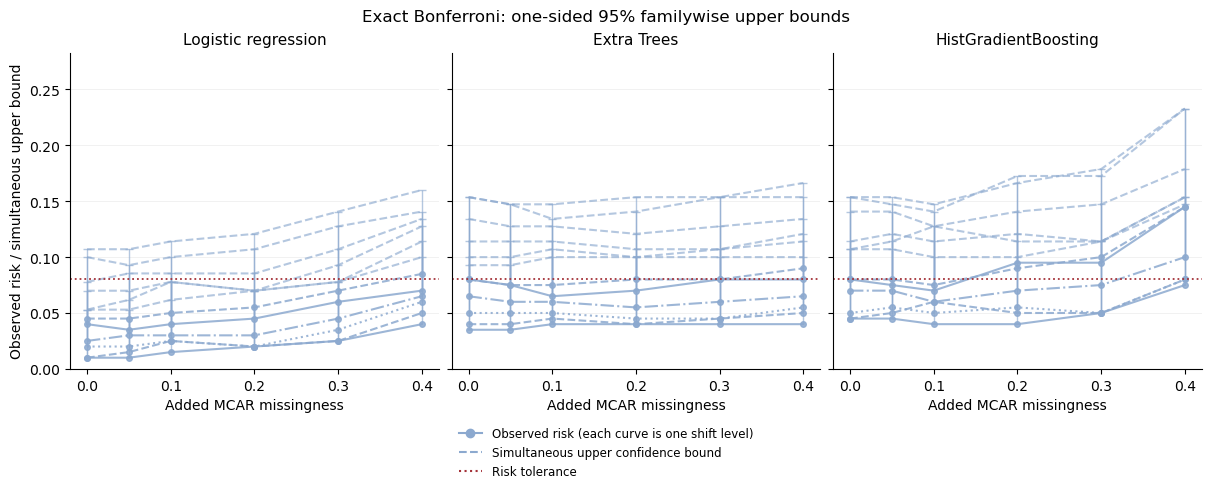

In [19]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


wdbc_detail, wdbc_summary = run.section(
    "wdbc", SECTIONS["wdbc"]
)

models = [
    "Logistic regression",
    "Extra Trees",
    "HistGradientBoosting",
]

# Shared categorical colors across all assurance maps
region_colors = REGION_COLORS
header_color = HEADER_COLOR

cmap = ListedColormap([region_colors[k] for k in ("safe", "borderline", "uncertified")])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap.N)

primary = wdbc_detail.loc[
    (wdbc_detail["design"] == "primary")
    & (wdbc_detail["method"] == "exact_bonferroni")
].copy()

fig, axes = plt.subplots(
    1, len(models),
    figsize=(12, 4.8),
    sharex=True,
    sharey=True,
    layout="constrained",
)

for ax, model in zip(axes, models):
    # Match screenshot: missingness on x, shift on y
    upper = (
        primary.loc[primary["Model"] == model]
        .pivot(
            index="Shift",
            columns="Missingness",
            values="upper",
        )
        .sort_index()
        .sort_index(axis=1)
    )

    upper_values = upper.to_numpy()
    regions = np.select(
        [upper_values <= 0.08, upper_values <= 0.10],
        [0, 1],
        default=2,
    ).astype(float)
    regions[~np.isfinite(upper_values)] = np.nan

    ax.pcolormesh(
        upper.columns.to_numpy(),
        upper.index.to_numpy(),
        regions,
        shading="nearest",
        cmap=cmap,
        norm=norm,
        rasterized=True,
    )

    ax.set_title(
        model,
        fontsize=11,
        fontweight="bold",
        color="white",
        pad=12,
        bbox={
            "facecolor": header_color,
            "edgecolor": header_color,
            "boxstyle": "round,pad=0.5",
        },
    )

    ax.set_xlabel("Missingness severity")
    ax.tick_params(labelsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Distribution-shift severity")

fig.suptitle(
    "WDBC: Statistical Assurance Maps",
    fontsize=15,
    fontweight="bold",
    color=header_color,
)

fig.legend(
    handles=[
        Patch(
            facecolor=region_colors["safe"],
            label="Certified safe at τ = 0.08",
        ),
        Patch(
            facecolor=region_colors["borderline"],
            label="Borderline: certified only at τ = 0.10",
        ),
        Patch(
            facecolor=region_colors["uncertified"],
            label="Not certified at either tolerance",
        ),
    ],
    loc="outside lower center",
    ncol=3,
    frameon=False,
    fontsize=9,
)

run.fig.mkdir(parents=True, exist_ok=True)

for extension in ["png", "pdf"]:
    fig.savefig(
        run.fig / f"wdbc_assurance_maps.{extension}",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

display(fig)
plt.close(fig)

# Companion figure: existing simultaneous upper confidence bounds.
wdbc_bound_data = primary.assign(eligible=True)
risk_bound_figure(wdbc_bound_data, 'risk', 'upper', 'Shift',
                  'wdbc_upper_bounds', run.fig, 0.08)


## 7. Sample size, dependence, and the cost of multiplicity
The sensitivity study compares all certification methods on the same losses and reports
**paired** ARR differences, with Monte Carlo standard errors, relative to normal Bonferroni,
exact Bonferroni, and exact Holm. Any efficiency gain must be read alongside coverage and
containment. A wider certified region is not a valid improvement if its guarantee fails.

Running sensitivity (full)
Completed sensitivity: 14.7s


,n,rho,method,simultaneous_coverage,containment,ARR,UCP
0,500,0.55,pointwise,0.4733,0.8800,0.4293,0.0141
1,500,0.55,normal_bonferroni,0.9100,0.9967,0.1664,0.0005
2,500,0.55,multiplier,0.9033,0.9967,0.1752,0.0005
3,500,0.55,exact_bonferroni,0.9467,0.9967,0.1383,0.0006
4,500,0.55,hoeffding,1.0000,1.0000,0.0407,0.0000
5,500,0.55,holm,NaN,0.9967,0.1407,0.0006
6,1000,0.55,pointwise,0.5367,0.9500,0.4976,0.0047
7,1000,0.55,normal_bonferroni,0.9600,0.9967,0.2698,0.0004
8,1000,0.55,multiplier,0.9500,0.9967,0.2819,0.0004
9,1000,0.55,exact_bonferroni,0.9733,1.0000,0.2457,0.0000


,n,rho,baseline,replications,ARR_gain,ARR_gain_mcse
0,500,0.55,normal_bonferroni,300,0.0088,0.0016
1,1000,0.10,normal_bonferroni,300,-0.0000,0.0008
2,1000,0.55,normal_bonferroni,300,0.0121,0.0016
3,1000,0.90,normal_bonferroni,300,0.0660,0.0038
4,5000,0.55,normal_bonferroni,300,0.0121,0.0017
5,500,0.55,exact_bonferroni,300,0.0369,0.0029
6,1000,0.10,exact_bonferroni,300,0.0195,0.0020
7,1000,0.55,exact_bonferroni,300,0.0362,0.0029
8,1000,0.90,exact_bonferroni,300,0.0921,0.0041
9,5000,0.55,exact_bonferroni,300,0.0164,0.0019


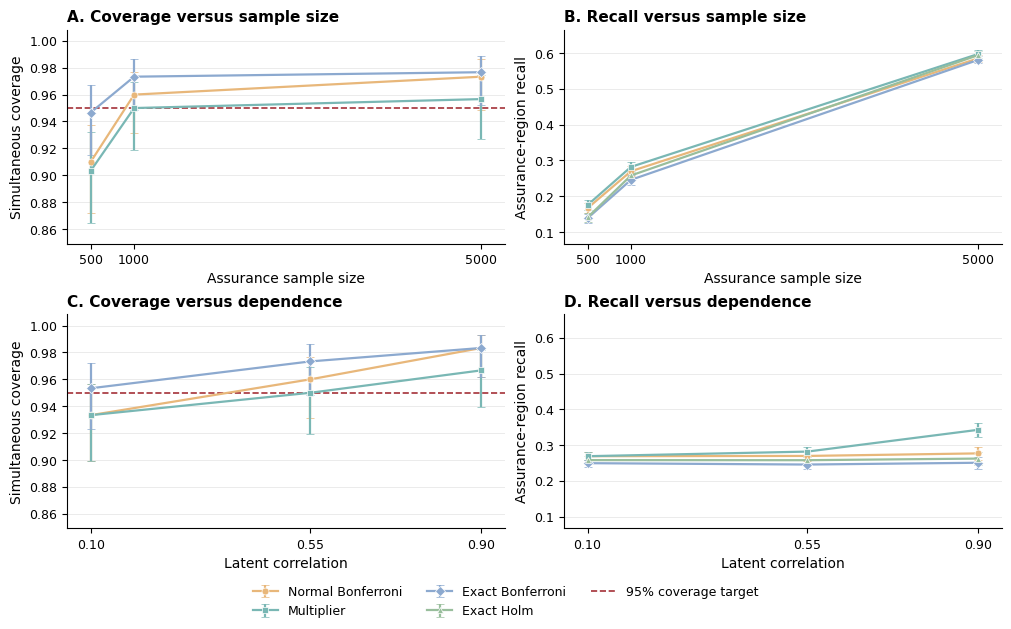

In [23]:
sensitivity_replications, sensitivity_summary = run.section(
    "sensitivity", SECTIONS["sensitivity"]
)

display(
    sensitivity_summary[
        ["n", "rho", "method", "simultaneous_coverage",
         "containment", "ARR", "UCP"]
    ].round(4)
)
display(pd.read_csv(run.out / "paired_efficiency_gains.csv").round(4))

methods = [
    "normal_bonferroni",
    "multiplier",
    "exact_bonferroni",
    "holm",
]

short_labels = {
    "normal_bonferroni": "Normal Bonferroni",
    "multiplier": "Multiplier",
    "exact_bonferroni": "Exact Bonferroni",
    "holm": "Exact Holm",
}

markers = {
    "normal_bonferroni": "o",
    "multiplier": "s",
    "exact_bonferroni": "D",
    "holm": "^",
}

# Same slices used in the original sensitivity figure
sample_size = sensitivity_summary.loc[
    np.isclose(sensitivity_summary["rho"], 0.55)
].copy()

dependence = sensitivity_summary.loc[
    sensitivity_summary["n"] == 1000
].copy()

if sample_size.empty or dependence.empty:
    raise ValueError(
        "Expected sensitivity slices rho=0.55 and n=1000 are missing."
    )

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 6.2),
    sharey="col",
    layout="constrained",
)

panels = [
    (sample_size, "n", "Assurance sample size"),
    (dependence, "rho", "Latent correlation"),
]

for row, (data, x_column, x_label) in enumerate(panels):
    for method in methods:
        results = (
            data.loc[data["method"] == method]
            .sort_values(x_column)
        )

        if results.empty:
            continue

        style = {
            "color": COLORS[method],
            "marker": markers[method],
            "markersize": 5,
            "linewidth": 1.6,
            "markeredgecolor": "white",
            "markeredgewidth": 0.5,
        }

        # Holm is a testing procedure, not a simultaneous upper band
        if method != "holm":
            axes[row, 0].errorbar(
                results[x_column],
                results["simultaneous_coverage"],
                yerr=np.vstack([results["simultaneous_coverage"]-results["simultaneous_coverage_lo"], results["simultaneous_coverage_hi"]-results["simultaneous_coverage"]]),
                capsize=3, **style,
            )

        axes[row, 1].errorbar(
            results[x_column],
            results["ARR"],
            yerr=1.96*results["ARR_mcse"], capsize=3,
            label=short_labels[method],
            **style,
        )

    axes[row, 0].axhline(
        0.95,
        color="#A43138",
        linestyle="--",
        linewidth=1.2,
        zorder=1,
    )

    for ax in axes[row]:
        ax.set_xlabel(x_label)
        ax.set_xticks(sorted(data[x_column].unique()))
        ax.tick_params(labelsize=9)
        ax.grid(axis="y", color="#DDDDDD", linewidth=0.6, alpha=0.7)
        ax.set_axisbelow(True)
        ax.margins(x=0.06)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

# Tight but identical y-scales for corresponding metrics
shown = pd.concat([sample_size, dependence], ignore_index=True)
shown = shown.loc[shown["method"].isin(methods)]

coverage_values = shown.loc[
    shown["method"] != "holm", ["simultaneous_coverage_lo", "simultaneous_coverage_hi"]
].to_numpy().ravel()

arr_values = np.concatenate([(shown.ARR-1.96*shown.ARR_mcse).to_numpy(), (shown.ARR+1.96*shown.ARR_mcse).to_numpy()])

def probability_limits(values, include=(), minimum_padding=0.015):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    values = np.concatenate([values, np.asarray(include, dtype=float)])

    if values.size == 0:
        return 0, 1

    lower, upper = values.min(), values.max()
    padding = max(minimum_padding, 0.12 * (upper - lower))
    return max(0, lower - padding), min(1.01, upper + padding)

coverage_limits = probability_limits(
    coverage_values,
    include=(0.95,),
)
arr_limits = probability_limits(arr_values)

for ax in axes[:, 0]:
    ax.set_ylim(*coverage_limits)
    ax.set_ylabel("Simultaneous coverage")

for ax in axes[:, 1]:
    ax.set_ylim(*arr_limits)
    ax.set_ylabel("Assurance-region recall")

titles = [
    "A. Coverage versus sample size",
    "B. Recall versus sample size",
    "C. Coverage versus dependence",
    "D. Recall versus dependence",
]

for ax, title in zip(axes.flat, titles):
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")

# One shared legend
from matplotlib.lines import Line2D

handles, labels = axes[0, 1].get_legend_handles_labels()
handles.append(
    Line2D(
        [0], [0],
        color="#A43138",
        linestyle="--",
        linewidth=1.2,
    )
)
labels.append("95% coverage target")

fig.legend(
    handles,
    labels,
    loc="outside lower center",
    ncol=3,
    frameon=False,
    fontsize=9,
)

run.fig.mkdir(parents=True, exist_ok=True)

for extension in ["png", "pdf"]:
    fig.savefig(
        run.fig / f"sensitivity_compact.{extension}",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

display(fig)
plt.close(fig)


## 8. Bootstrap Monte Carlo error, runtime, and adverse regimes
For each fixed loss matrix, repeated seeds at B = 200, 1,000, and 5,000 measure bootstrap
critical-value variability and inference time. This is a timing experiment, not a guarantee
that one bootstrap size suffices in all settings. The direct sampler costs O(B n K); the
covariance route costs O(n K² + K³ + B K²), with different memory tradeoffs.

Additional studies use bounded continuous Beta losses, rare binary errors, and a larger
125-environment family. Exact binomial methods apply only to binary losses. Bounded loss
does not imply that the Gaussian approximation is accurate when events are rare. Adversarial
adaptive shifts, unbounded heavy-tailed losses, and high-dimensional continuous environment
geometry are not claimed to be addressed by these stress tests.

Running bootstrap_and_stress (full)
Completed bootstrap_and_stress: 9.9s


,n,K,B,replications,critical,critical_mcse,n_certified,n_certified_mcse,seconds,seconds_mcse
0,500,25,200,25,2.81898,0.01884,5.08,0.15188,0.00187,0.00014
1,500,25,1000,25,2.79548,0.00848,5.32,0.09522,0.00220,0.00004
2,500,25,5000,25,2.79620,0.00523,5.20,0.08165,0.00570,0.00017
3,1000,25,200,25,2.80609,0.02894,4.60,0.20817,0.00183,0.00006
4,1000,25,1000,25,2.79257,0.00889,4.84,0.07483,0.00280,0.00019
5,1000,25,5000,25,2.79390,0.00368,4.96,0.04000,0.00774,0.00138
6,1000,125,200,25,3.25695,0.02269,12.28,0.22000,0.01039,0.00048
7,1000,125,1000,25,3.21348,0.00969,12.40,0.11547,0.01271,0.00076
8,1000,125,5000,25,3.21002,0.00348,12.12,0.06633,0.04134,0.00369


,scenario,method,simultaneous_coverage,simultaneous_coverage_lo,simultaneous_coverage_hi,containment,ARR
0,bounded_continuous,pointwise,0.265,0.2087,0.3302,0.970,0.6579
1,bounded_continuous,normal_bonferroni,0.925,0.8800,0.9540,1.000,0.4693
2,bounded_continuous,multiplier,0.925,0.8800,0.9540,1.000,0.4696
3,bounded_continuous,hoeffding,1.000,0.9812,1.0000,1.000,0.0082
4,rare_binary,pointwise,0.260,0.2041,0.3249,0.945,0.6082
5,rare_binary,normal_bonferroni,0.780,0.7176,0.8318,0.995,0.4550
6,rare_binary,multiplier,0.780,0.7176,0.8318,0.990,0.5023
7,rare_binary,exact_bonferroni,0.995,0.9722,0.9991,1.000,0.3791
8,rare_binary,hoeffding,1.000,0.9812,1.0000,1.000,0.0000
9,rare_binary,holm,NaN,NaN,NaN,1.000,0.3791


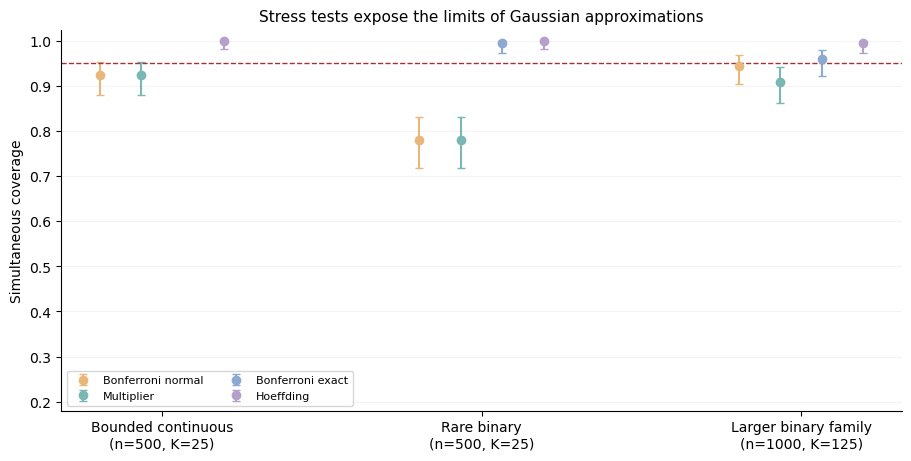

In [25]:
bootstrap_replications, stress_replications = run.section('bootstrap_and_stress', SECTIONS['bootstrap_and_stress'])
display(pd.read_csv(run.out / 'bootstrap_runtime_summary.csv').round(5))
display(pd.read_csv(run.out / 'stress_summary.csv')[['scenario', 'method',
    'simultaneous_coverage', 'simultaneous_coverage_lo', 'simultaneous_coverage_hi',
    'containment', 'ARR']].round(4))
fig = stress_figure(run)
ax = fig.axes[0]
stress_summary = pd.read_csv(run.out / 'stress_summary.csv')
lo = stress_summary.simultaneous_coverage_lo.min()
ax.set_ylim(max(0, lo-.025), 1.025)
finish_figure(fig, 'stress')

## 9. Continuous SAR and the Lipschitz requirement
For a known global bound $|R(e)-R(e')|\le L_R\|e-e'\|$, the envelope
$U^{\mathrm{cont}}(e)=\min_k\{U_k+L_R\|e-e_k\|\}\wedge1$ covers all continuous risks
on the grid-coverage event. This is a standard consequence of simultaneous coverage and
smoothness, not a new bootstrap theorem.

The bilinear example $R(m,s)=.24+.12m+.10s+.05ms$ on $[0,.4]\times[0,.6]$ has the analytic
bound $L_R=\sqrt{.15^2+.12^2}$. Dense-mesh containment/recall are numerical diagnostics,
not a numerical proof over every point. The proof supplies continuous coverage when the
bound is valid. Files also record sensitivity to half and twice the analytic bound; the
half-bound scenario is not asserted valid.

**Do not estimate a global Lipschitz upper bound by the maximum observed grid slope.**
Even independent pilot slopes do not control unseen behavior between grid points. Without
external smoothness information, report finite-grid results. If a separately justified random
upper bound fails with probability delta, the combined coverage budget is alpha + delta.

Running continuous (full)
Completed continuous: 8.3s


,method,grid_coverage,containment,ARR,UCP
0,multiplier,0.940,0.975,0.4599,0.0004
1,exact_bonferroni,0.965,0.980,0.4038,0.0001
2,hoeffding,1.000,1.000,0.1849,0.0000


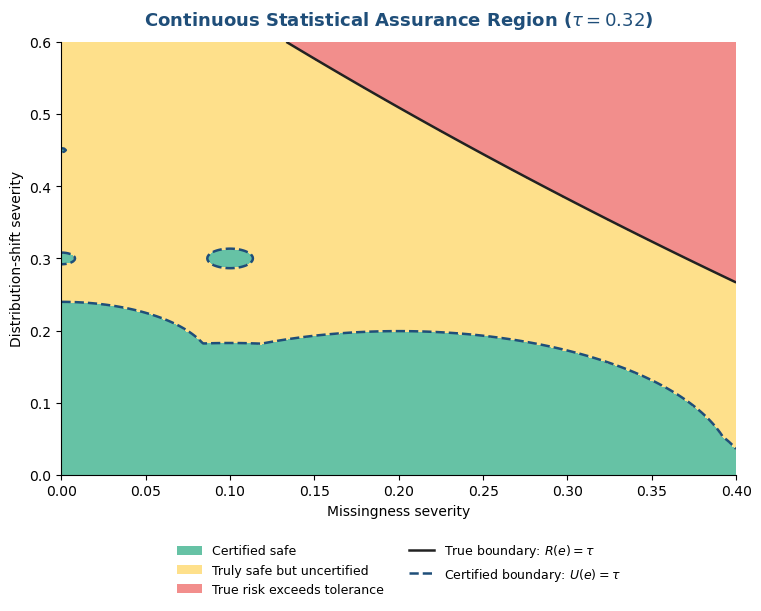

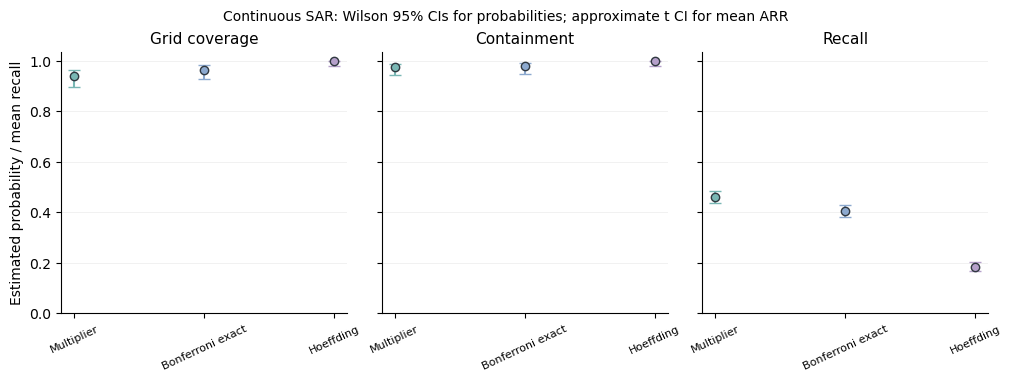

In [27]:
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sciguard.experiments import seeded
from sciguard.simulation import correlated_bernoulli
from sciguard.continuous import continuous_upper_envelope

continuous_replications, continuous_summary = run.section(
    "continuous", SECTIONS["continuous"]
)

display(
    continuous_summary[
        ["method", "grid_coverage", "containment", "ARR", "UCP"]
    ].round(4)
)

# Reconstruct the same first multiplier replication used
# by the original continuous_example.csv.
cfg = run.cfg
tau = 0.32

grid = np.array([
    (missingness, shift)
    for missingness in np.linspace(0, 0.4, 5)
    for shift in np.linspace(0, 0.6, 5)
])

def analytic_risk(points):
    m = points[:, 0]
    s = points[:, 1]
    return 0.24 + 0.12*m + 0.10*s + 0.05*m*s

losses = correlated_bernoulli(
    cfg.n_assure,
    analytic_risk(grid),
    0.55,
    seeded(cfg, 70, 0),
)

result = certify(
    losses,
    tau,
    method="multiplier",
    n_boot=cfg.bootstrap_draws,
    rng=seeded(cfg, 71, 0),
)

# Evaluate the continuous envelope directly on a dense mesh.
missingness = np.linspace(0, 0.4, 301)
shift = np.linspace(0, 0.6, 301)
M, S = np.meshgrid(missingness, shift)
query = np.column_stack([M.ravel(), S.ravel()])

R = analytic_risk(query).reshape(M.shape)

# Global Lipschitz bound used in the original experiment
lipschitz = np.hypot(0.15, 0.12)

U = continuous_upper_envelope(
    grid,
    result.upper,
    query,
    lipschitz,
).reshape(M.shape)

certified = U <= tau
truly_safe = R <= tau

# Preserve any certification failure instead of hiding it.
regions = np.full(R.shape, 2)
regions[truly_safe & ~certified] = 1
regions[truly_safe & certified] = 0
regions[~truly_safe & certified] = 3

colors = [REGION_COLORS[k] for k in ('safe','borderline','uncertified','failure')]

fig, ax = plt.subplots(
    figsize=(7.5, 6),
    layout="constrained",
)

ax.contourf(
    M, S, regions,
    levels=[-0.5, 0.5, 1.5, 2.5, 3.5],
    cmap=ListedColormap(colors),
    antialiased=False,
)

legend_handles = [
    Patch(facecolor=colors[0], label="Certified safe"),
    Patch(facecolor=colors[1], label="Truly safe but uncertified"),
    Patch(facecolor=colors[2], label="True risk exceeds tolerance"),
]

# Known true-risk boundary
if R.min() < tau < R.max():
    ax.contour(
        M, S, R,
        levels=[tau],
        colors="#222222",
        linewidths=1.8,
        linestyles="solid",
    )
    legend_handles.append(
        Line2D(
            [0], [0],
            color="#222222",
            linewidth=1.8,
            label=r"True boundary: $R(e)=\tau$",
        )
    )

# Certified SAR boundary
if U.min() < tau < U.max():
    ax.contour(
        M, S, U,
        levels=[tau],
        colors="#1F4E79",
        linewidths=1.8,
        linestyles="dashed",
    )
    legend_handles.append(
        Line2D(
            [0], [0],
            color="#1F4E79",
            linestyle="--",
            linewidth=1.8,
            label=r"Certified boundary: $U(e)=\tau$",
        )
    )

if np.any(certified & ~truly_safe):
    legend_handles.append(
        Patch(
            facecolor=colors[3],
            label="Certified despite true risk exceeding tolerance",
        )
    )

ax.set(
    xlim=(0, 0.4),
    ylim=(0, 0.6),
    xlabel="Missingness severity",
    ylabel="Distribution-shift severity",
)

ax.set_title(
    r"Continuous Statistical Assurance Region ($\tau=0.32$)",
    fontsize=13,
    fontweight="bold",
    color="#1F4E79",
    pad=12,
)

ax.tick_params(labelsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=2,
    frameon=False,
    fontsize=9,
)

run.fig.mkdir(parents=True, exist_ok=True)

for extension in ["png", "pdf"]:
    fig.savefig(
        run.fig / f"continuous_sar_contours.{extension}",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

display(fig)
plt.close(fig)

# Monte Carlo uncertainty for repeated continuous-SAR experiments.
metrics = [('grid_coverage','Grid coverage'), ('containment','Containment'), ('ARR','Recall')]
methods = ['multiplier','exact_bonferroni','hoeffding']
fig, axes = plt.subplots(1,3,figsize=(10,3.7),sharey=True,layout='constrained')
for ax,(metric,title) in zip(axes,metrics):
    for i,method in enumerate(methods):
        v=continuous_replications.loc[continuous_replications.method==method,metric].dropna()
        if metric=='ARR':
            mean,lo,hi=mean_ci(v)
        else:
            mean=v.mean();_,lo,hi=wilson_interval(v.to_numpy())
        if np.isfinite(lo):
            ax.errorbar(i,mean,yerr=[[mean-lo],[hi-mean]],fmt='o',color=COLORS[method],
                        markeredgecolor=REFERENCE_COLOR,capsize=4)
    ax.set(title=title,xticks=range(3),xticklabels=[LABELS[m] for m in methods],ylim=(0,1.035))
    ax.tick_params(axis='x',rotation=25,labelsize=8)
    style_axis(ax)
axes[0].set_ylabel('Estimated probability / mean recall')
fig.suptitle('Continuous SAR: Wilson 95% CIs for probabilities; approximate t CI for mean ARR',fontsize=10)
finish_figure(fig,'continuous_uncertainty')


## 10. Environment design and independent pilot refinement
Choose the scientific loss and deployment axes; set ranges from external knowledge;
freeze preprocessing and the candidate family; choose sample size for a meaningful margin;
use a pilot to prioritize a finite family; then evaluate that frozen family on **independent**
assurance rows. The example selects grid points near a pilot-estimated boundary plus coordinate
extremes. Its exact-binomial guarantee is conditional on the selected family, not on the
entire continuous rectangle.

The Hoeffding planning inequality $n\ge\log(K/\alpha)/(2\epsilon^2)$ ensures the additive
bound width is at most epsilon. It does not ensure a desired recall or a desired probability
of certification, which also depends on the true margin and sampling variation.

Repeated deployment checks are not time-uniform by default. A simple, conservative extension
allocates $\alpha_t=\alpha/[t(t+1)]$ to each round with valid conditional finite-sample
inference and fresh assurance data. The union bound then controls any false certification
over all rounds. This is standard alpha spending, not a newly optimal sequential SAR method.

In [29]:
pilot_replications, planning_table = run.section('pilot_design', SECTIONS['pilot_design'])
display(pd.read_csv(run.out / 'pilot_design_summary.csv').round(4))
display(planning_table)


Running pilot_design (full)
Completed pilot_design: 0.8s


,containment,ARR,UCP,n_certified,n_true_safe,rep,K_selected,simultaneous_coverage,replications
0,1.0,0.1616,0.0,3.805,23.38,99.5,32.435,0.96,200


,K,margin,alpha,hoeffding_n
0,25,0.02,0.05,7769
1,25,0.05,0.05,1243
2,25,0.10,0.05,311
3,100,0.02,0.05,9502
4,100,0.05,0.05,1521
5,100,0.10,0.05,381
6,500,0.02,0.05,11513
7,500,0.05,0.05,1843
8,500,0.10,0.05,461


## 11. MIMIC-IV protocol: prerequisites and temporal corrections
The credentialed MIMIC-IV v3.1 analysis has been executed locally. Its aggregate outputs are stored
in `results/mimic_local/` and `figures/mimic_local/`, and the frozen protocol, including the
prespecified `tau = 0.35` and its rationale, is in `config/mimic_protocol.json`. The package contains
no patient-level data. Re-executing the cells below requires separately obtained credentialed access:
set `MIMIC_IV_PATH` to the local dataset directory and `SCIGUARD_RUN_MIMIC=1` before starting the
kernel. Without them the MIMIC cells are skipped, and the stored aggregate outputs remain the evidence
reported in the manuscript.

The tolerance `tau = 0.35` is an operational workflow threshold fixed before examining deployment
outcomes. It is not a clinical standard, and no universal clinical tolerance is inferred from it.

**Cohort:** first eligible adult hospitalization per patient; in-hospital mortality outcome;
admission-table demographic/admission variables; train-only preprocessing; 0.5 decision
threshold. Patient identifiers, mortality flags, discharge/death dates, and length of stay
are excluded from predictors. Availability of the admission-table fields at the intended
decision time still requires an author/data audit; this is a limited clinical baseline.

**Temporal design:** `anchor_year_group` describes the patient's anchor year, not every
admission. The loader adds `year(admittime) - anchor_year` to its endpoints, uses configurable
one-year padding for approximate year alignment, and restricts intervals to the declared
dataset coverage. Source intervals end by the cutoff; deployment intervals begin after it;
overlapping intervals are excluded. Deployment labels are approximate admission intervals
and may overlap one another in calendar time. They are not exact admission years or sites.
Top-coded age 91 is retained as a category/provenance indicator rather than interpreted as
exact age or used to exclude the oldest patients.

Official date guidance: https://physionet.org/content/mimiciv/3.1/ (accessed September 27, 2026).
The one-year padding is a conservative analysis choice, not an official exact-date guarantee.

### 11.1 Dependence, class imbalance, and natural missingness
Within each domain, missingness levels reuse the same patients. The common-row influence
vector is $\widehat\psi_{i,d,m}=G_{id}(L_i^{(m)}-\widehat R_{d,m})/\widehat p_d$.
Overlapping groups and unequal counts are supported without truncating or inventing pairings.
The multiplier ratio-estimator route assumes nonvanishing group probabilities as well as
appropriate row sampling. Exact group-conditional binomial and Hoeffding bands are supplied.

All models, missingness levels, and domains belong to **one** simultaneous family. Small
domains remain visible and unvalidated. An always-survive baseline, mortality prevalence,
sensitivity/specificity, balanced accuracy, AUROC, and AUPRC reveal when low 0-1 risk is
uninformative under class imbalance. These diagnostic metrics do not inherit the 0-1-risk
certification guarantee. Native feature missingness is reported separately from added MCAR
and total missingness. Adding MCAR does not establish robustness to clinical MAR/MNAR.

Only aggregate result tables are saved. No row-level cohort, patient identifiers, or fitted
model is exported. Source file hashes and the frozen configuration support local provenance.
One admission per patient removes repeated-patient rows; it does not prove exchangeability
or eliminate hospital/time clustering. Actual-data validation remains required.

In [82]:
# Credentialed MIMIC-IV execution is opt-in so that the notebook runs end to end without
# credentialed data. To re-execute locally, set SCIGUARD_RUN_MIMIC=1 and MIMIC_IV_PATH before
# starting the kernel, or uncomment the next line.
# os.environ['SCIGUARD_RUN_MIMIC'] = '1'
RUN_MIMIC = os.environ.get('SCIGUARD_RUN_MIMIC', '0') == '1'

In [61]:
if RUN_MIMIC:
    import os
    from pathlib import Path



    # ROOT is the project directory defined in the notebook setup.
    project_root = Path(ROOT).resolve()

    def contains_mimic_data(folder):
        hosp = folder / "hosp"
        return all(
            any((hosp / filename).is_file() for filename in alternatives)
            for alternatives in [
                ["patients.csv", "patients.csv.gz"],
                ["admissions.csv", "admissions.csv.gz"],
            ]
        )

    # Search common locations first.
    candidates = [
        project_root / "mimic-iv-3.1",
        project_root / "data" / "mimic-iv-3.1",
        project_root.parent / "mimic-iv-3.1",
        project_root,  # Dataset files may be directly under ROOT/hosp.
    ]

    # Also search nested folders within the project.
    candidates.extend(
        sorted(
            path for path in project_root.rglob("mimic-iv-3.1")
            if path.is_dir()
        )
    )

    matches = list(dict.fromkeys(
        path.resolve()
        for path in candidates
        if contains_mimic_data(path)
    ))

    if not matches:
        raise FileNotFoundError(
            "MIMIC-IV data were not found. Place the mimic-iv-3.1 folder "
            "inside the project folder, inside its data folder, or beside "
            "the project folder. It must contain hosp/patients.csv(.gz) "
            "and hosp/admissions.csv(.gz)."
        )

    if len(matches) > 1:
        raise RuntimeError(
            "Multiple MIMIC-IV datasets were found; keep one dataset "
            "in the search locations to avoid using the wrong copy:\n"
            + "\n".join(str(path) for path in matches)
        )

    MIMIC_ROOT = matches[0]
    os.environ["MIMIC_IV_PATH"] = str(MIMIC_ROOT)

    print("MIMIC root:", MIMIC_ROOT)
    print("Root exists:", MIMIC_ROOT.exists())
    print("HOSP exists:", (MIMIC_ROOT / "hosp").exists())
    print("ICU exists:", (MIMIC_ROOT / "icu").exists())
else:
    print('MIMIC execution disabled; public/synthetic sections remain available.')


MIMIC root: C:\Users\maale\OneDrive - University of North Carolina at Charlotte\Desktop\NC A&T State Uni\Research\SciGuard_JMLR_Revision4_Project\mimic-iv-3.1
Root exists: True
HOSP exists: True
ICU exists: True


In [63]:
if RUN_MIMIC:
    print("Admissions files:")
    print(list((MIMIC_ROOT / "hosp").glob("admissions*")))

    print("\nPatients files:")
    print(list((MIMIC_ROOT / "hosp").glob("patients*")))

    print("\nICU stay files:")
    print(list((MIMIC_ROOT / "icu").glob("icustays*")))


Admissions files:
[WindowsPath('C:/Users/maale/OneDrive - University of North Carolina at Charlotte/Desktop/NC A&T State Uni/Research/SciGuard_JMLR_Revision4_Project/mimic-iv-3.1/hosp/admissions.csv.gz')]

Patients files:
[WindowsPath('C:/Users/maale/OneDrive - University of North Carolina at Charlotte/Desktop/NC A&T State Uni/Research/SciGuard_JMLR_Revision4_Project/mimic-iv-3.1/hosp/patients.csv.gz')]

ICU stay files:
[WindowsPath('C:/Users/maale/OneDrive - University of North Carolina at Charlotte/Desktop/NC A&T State Uni/Research/SciGuard_JMLR_Revision4_Project/mimic-iv-3.1/icu/icustays.csv.gz')]


RUN_MIMIC: True
MIMIC_ROOT: C:\Users\maale\OneDrive - University of North Carolina at Charlotte\Desktop\NC A&T State Uni\Research\SciGuard_JMLR_Revision4_Project\mimic-iv-3.1


,stage,N
0,joined_admissions,546028
1,valid_adult_admissions,546028
2,one_first_adult_admission_per_patient,223452
3,source,106864
4,deployment,35114
5,excluded_overlap,81474


,TemporalDomain,Model,Missingness,method,n,risk,upper,certified,eligible,critical,tau,alpha
0,2017 - 2021,Logistic regression,0.0,multiplier,2312,0.0061,0.0102,True,True,2.5378,0.35,0.05
1,2017 - 2021,Logistic regression,0.1,multiplier,2312,0.0065,0.0107,True,True,2.5378,0.35,0.05
2,2017 - 2021,Logistic regression,0.2,multiplier,2312,0.0065,0.0107,True,True,2.5378,0.35,0.05
3,2017 - 2021,Logistic regression,0.3,multiplier,2312,0.0065,0.0107,True,True,2.5378,0.35,0.05
4,2017 - 2021,HistGradientBoosting,0.0,multiplier,2312,0.0061,0.0102,True,True,2.5378,0.35,0.05
...,...,...,...,...,...,...,...,...,...,...,...,...
283,2022 - 2022,HistGradientBoosting,0.3,holm,32,0.0312,NaN,False,False,NaN,0.35,0.05
284,2022 - 2022,Always survive,0.0,holm,32,0.0312,NaN,False,False,NaN,0.35,0.05
285,2022 - 2022,Always survive,0.1,holm,32,0.0312,NaN,False,False,NaN,0.35,0.05
286,2022 - 2022,Always survive,0.2,holm,32,0.0312,NaN,False,False,NaN,0.35,0.05


,Model,TemporalDomain,Missingness,n,mortality_prevalence,risk,source_holdout_risk,sensitivity,specificity,balanced_accuracy,AUROC,AUPRC
0,Logistic regression,2017 - 2021,0.0,2312,0.0061,0.0061,0.0184,0.0000,1.0000,0.5000,0.8047,0.0990
1,Logistic regression,2018 - 2022,0.0,1645,0.0073,0.0073,0.0184,0.0000,1.0000,0.5000,0.8706,0.0687
2,Logistic regression,2019 - 2022,0.0,29419,0.0371,0.0389,0.0184,0.0495,0.9963,0.5229,0.8437,0.1764
3,Logistic regression,2020 - 2022,0.0,1282,0.0101,0.0101,0.0184,0.0000,1.0000,0.5000,0.9141,0.1044
4,Logistic regression,2021 - 2022,0.0,424,0.0118,0.0118,0.0184,0.0000,1.0000,0.5000,0.9513,0.1728
...,...,...,...,...,...,...,...,...,...,...,...,...
67,Always survive,2018 - 2022,0.3,1645,0.0073,0.0073,0.0184,0.0000,1.0000,0.5000,0.5000,0.0073
68,Always survive,2019 - 2022,0.3,29419,0.0371,0.0371,0.0184,0.0000,1.0000,0.5000,0.5000,0.0371
69,Always survive,2020 - 2022,0.3,1282,0.0101,0.0101,0.0184,0.0000,1.0000,0.5000,0.5000,0.0101
70,Always survive,2021 - 2022,0.3,424,0.0118,0.0118,0.0184,0.0000,1.0000,0.5000,0.5000,0.0118


,TemporalDomain,Feature,n,natural_missing_fraction
0,2017 - 2021,age,2312,0.0000
1,2017 - 2021,age_topcoded,2312,0.0000
2,2017 - 2021,gender,2312,0.0000
3,2017 - 2021,admission_type,2312,0.0000
4,2017 - 2021,admission_location,2312,0.0000
5,2017 - 2021,insurance,2312,0.0138
6,2017 - 2021,marital_status,2312,0.0035
7,2017 - 2021,race,2312,0.0000
8,2018 - 2022,age,1645,0.0000
9,2018 - 2022,age_topcoded,1645,0.0000


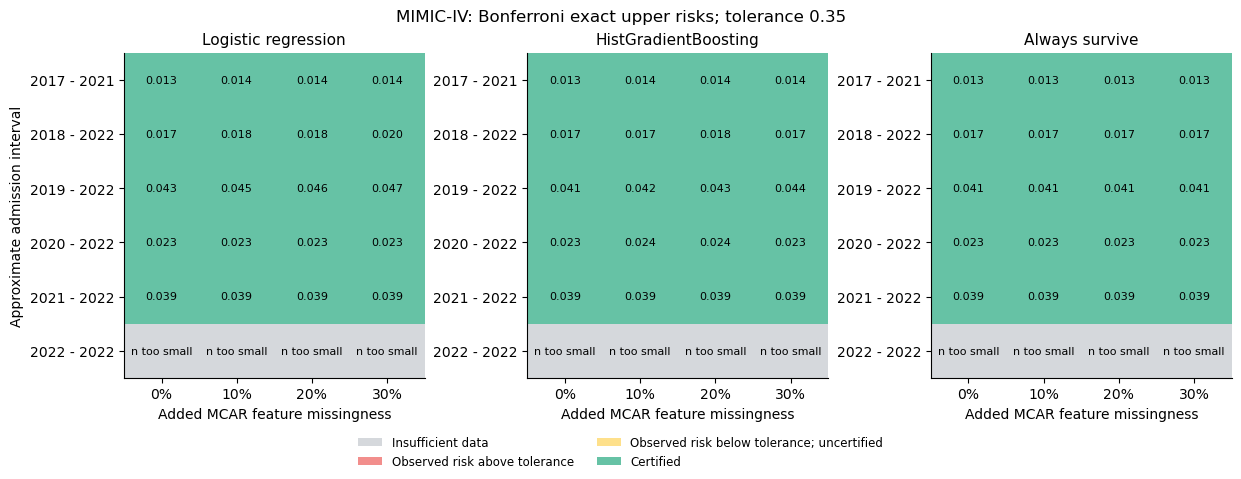

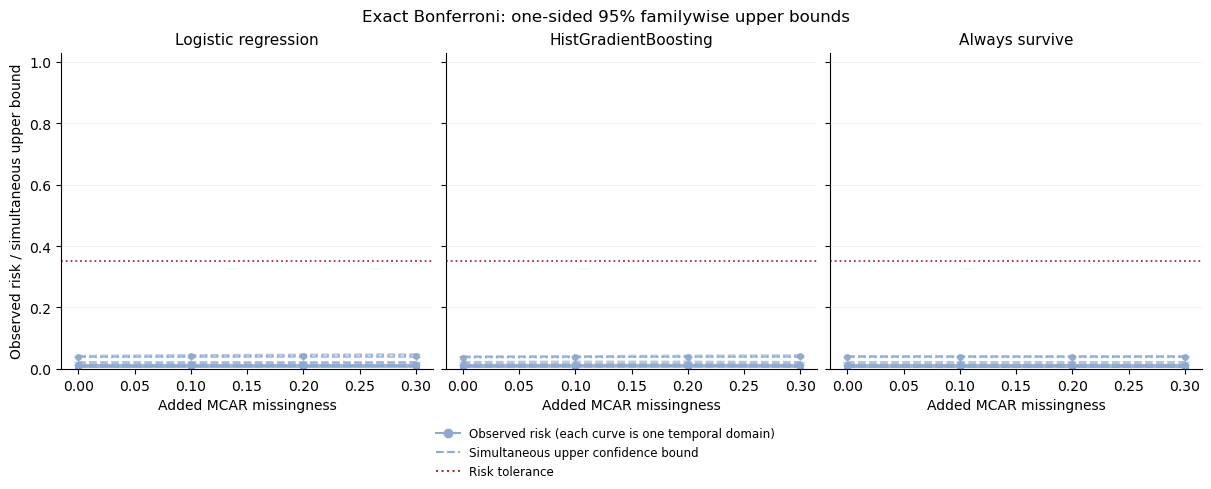

In [65]:
from sciguard.mimic import run_mimic

MIMIC_CONFIG_PATH = ROOT / 'config/mimic_protocol.json'
MIMIC_CONFIG = json.loads(MIMIC_CONFIG_PATH.read_text())

# Prespecify the acceptable risk threshold BEFORE running MIMIC
MIMIC_CONFIG["tau"] = 0.35

MIMIC_CONFIG["tau_rationale"] = (
    "We prespecify tau = 0.35 as an operational maximum tolerable "
    "0-1 classification error for evaluating SciGuard under MIMIC-IV "
    "deployment shifts. This threshold is fixed before examining the "
    "MIMIC-IV deployment results and is not tuned using the outcomes."
)

RUN_MIMIC = os.environ.get('SCIGUARD_RUN_MIMIC', '0') == '1'

MIMIC_ROOT = Path(
    os.environ.get(
        'MIMIC_IV_PATH',
        str(ROOT / 'data/mimic-iv')
    )
).expanduser()

print("RUN_MIMIC:", RUN_MIMIC)
print("MIMIC_ROOT:", MIMIC_ROOT)

if RUN_MIMIC:
    if not MIMIC_ROOT.is_dir():
        raise FileNotFoundError(
            'Requested MIMIC execution, but MIMIC_IV_PATH '
            'is not an existing dataset directory.'
        )

    mimic_tables, mimic_manifest = run_mimic(
        MIMIC_ROOT,
        MIMIC_CONFIG,
        ROOT / 'results/mimic_local'
    )

    run.manifest['external_benchmark'] = (
        'completed_credentialed_data'
    )

    display(mimic_tables['mimic_cohort_flow'])
    display(mimic_tables['mimic_results'].round(4))
    display(mimic_tables['mimic_diagnostics'].round(4))
    display(mimic_tables['mimic_natural_missingness'].round(4))

    from sciguard.plotting import mimic_decision_map
    # Make the package map use the same categorical colors.
    import matplotlib.colors as mpl_colors

    mimic_figure = mimic_decision_map(
        mimic_tables['mimic_results'],
        ROOT / 'figures/mimic_local'
    )

    for axis in mimic_figure.axes:
        for artist in axis.images:
            artist.set_cmap(ListedColormap([REGION_COLORS[k] for k in ('insufficient','uncertified','borderline','safe')]))
    if mimic_figure.legends:
        mimic_figure.legends[0].remove()
    mimic_figure.legend(handles=[Patch(facecolor=REGION_COLORS[k],label=label) for k,label in [
        ('insufficient','Insufficient data'),('uncertified','Observed risk above tolerance'),
        ('borderline','Observed risk below tolerance; uncertified'),('safe','Certified')]],
        loc='outside lower center',ncol=2,frameon=False)
    for name in ('mimic_iv_sar','mimic_sar_decision_map'):
        for ext in ('png','pdf'):
            mimic_figure.savefig(ROOT / 'figures/mimic_local' / f'{name}.{ext}', dpi=300, bbox_inches='tight')
    display(mimic_figure)
    plt.close(mimic_figure)

if RUN_MIMIC:
    risk_bound_figure(mimic_tables['mimic_results'], 'risk', 'upper', 'TemporalDomain',
                       'mimic_upper_bounds', ROOT / 'figures/mimic_local', MIMIC_CONFIG['tau'])
run.flush()


In [67]:
if RUN_MIMIC:
    # ============================================================
    # SAVE FINAL MIMIC-IV RESULTS FOR THE MANUSCRIPT
    # ============================================================

    import json
    from pathlib import Path

    MIMIC_RESULTS_DIR = ROOT / "results" / "mimic_local"
    MIMIC_FIG_DIR = ROOT / "figures" / "mimic_local"

    MIMIC_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    MIMIC_FIG_DIR.mkdir(parents=True, exist_ok=True)

    # Save all result tables
    mimic_tables["mimic_cohort_flow"].to_csv(
        MIMIC_RESULTS_DIR / "mimic_cohort_flow.csv",
        index=False
    )

    mimic_tables["mimic_results"].to_csv(
        MIMIC_RESULTS_DIR / "mimic_results.csv",
        index=False
    )

    mimic_tables["mimic_diagnostics"].to_csv(
        MIMIC_RESULTS_DIR / "mimic_diagnostics.csv",
        index=False
    )

    mimic_tables["mimic_natural_missingness"].to_csv(
        MIMIC_RESULTS_DIR / "mimic_natural_missingness.csv",
        index=False
    )

    # Save benchmark manifest
    with open(
        MIMIC_RESULTS_DIR / "mimic_manifest.json",
        "w"
    ) as f:
        json.dump(
            mimic_manifest,
            f,
            indent=2,
            default=str
        )

    # Save publication-quality figure
    mimic_figure.savefig(
        MIMIC_FIG_DIR / "mimic_sar_decision_map.pdf",
        bbox_inches="tight"
    )

    mimic_figure.savefig(
        MIMIC_FIG_DIR / "mimic_sar_decision_map.png",
        dpi=300,
        bbox_inches="tight"
    )

    print("Saved MIMIC-IV manuscript outputs:")
    print(MIMIC_RESULTS_DIR)
    print(MIMIC_FIG_DIR)


Saved MIMIC-IV manuscript outputs:
C:\Users\maale\OneDrive - University of North Carolina at Charlotte\Desktop\NC A&T State Uni\Research\SciGuard_JMLR_Revision4_Project\results\mimic_local
C:\Users\maale\OneDrive - University of North Carolina at Charlotte\Desktop\NC A&T State Uni\Research\SciGuard_JMLR_Revision4_Project\figures\mimic_local


In [69]:
if RUN_MIMIC:
    print(mimic_tables["mimic_results"].columns.tolist())

    display(
        mimic_tables["mimic_results"].round(4)
    )


['TemporalDomain', 'Model', 'Missingness', 'method', 'n', 'risk', 'upper', 'certified', 'eligible', 'critical', 'tau', 'alpha']


,TemporalDomain,Model,Missingness,method,n,risk,upper,certified,eligible,critical,tau,alpha
0,2017 - 2021,Logistic regression,0.0,multiplier,2312,0.0061,0.0102,True,True,2.5378,0.35,0.05
1,2017 - 2021,Logistic regression,0.1,multiplier,2312,0.0065,0.0107,True,True,2.5378,0.35,0.05
2,2017 - 2021,Logistic regression,0.2,multiplier,2312,0.0065,0.0107,True,True,2.5378,0.35,0.05
3,2017 - 2021,Logistic regression,0.3,multiplier,2312,0.0065,0.0107,True,True,2.5378,0.35,0.05
4,2017 - 2021,HistGradientBoosting,0.0,multiplier,2312,0.0061,0.0102,True,True,2.5378,0.35,0.05
...,...,...,...,...,...,...,...,...,...,...,...,...
283,2022 - 2022,HistGradientBoosting,0.3,holm,32,0.0312,NaN,False,False,NaN,0.35,0.05
284,2022 - 2022,Always survive,0.0,holm,32,0.0312,NaN,False,False,NaN,0.35,0.05
285,2022 - 2022,Always survive,0.1,holm,32,0.0312,NaN,False,False,NaN,0.35,0.05
286,2022 - 2022,Always survive,0.2,holm,32,0.0312,NaN,False,False,NaN,0.35,0.05


In [71]:
if RUN_MIMIC:
    mimic_tables["mimic_results"].round(4).to_latex(
        MIMIC_RESULTS_DIR / "mimic_results_table.tex",
        index=False,
        escape=False
    )


In [73]:
if RUN_MIMIC:
    display(mimic_tables["mimic_results"].round(4))
    display(mimic_tables["mimic_diagnostics"].round(4))
    display(mimic_tables["mimic_cohort_flow"])


,TemporalDomain,Model,Missingness,method,n,risk,upper,certified,eligible,critical,tau,alpha
0,2017 - 2021,Logistic regression,0.0,multiplier,2312,0.0061,0.0102,True,True,2.5378,0.35,0.05
1,2017 - 2021,Logistic regression,0.1,multiplier,2312,0.0065,0.0107,True,True,2.5378,0.35,0.05
2,2017 - 2021,Logistic regression,0.2,multiplier,2312,0.0065,0.0107,True,True,2.5378,0.35,0.05
3,2017 - 2021,Logistic regression,0.3,multiplier,2312,0.0065,0.0107,True,True,2.5378,0.35,0.05
4,2017 - 2021,HistGradientBoosting,0.0,multiplier,2312,0.0061,0.0102,True,True,2.5378,0.35,0.05
...,...,...,...,...,...,...,...,...,...,...,...,...
283,2022 - 2022,HistGradientBoosting,0.3,holm,32,0.0312,NaN,False,False,NaN,0.35,0.05
284,2022 - 2022,Always survive,0.0,holm,32,0.0312,NaN,False,False,NaN,0.35,0.05
285,2022 - 2022,Always survive,0.1,holm,32,0.0312,NaN,False,False,NaN,0.35,0.05
286,2022 - 2022,Always survive,0.2,holm,32,0.0312,NaN,False,False,NaN,0.35,0.05


,Model,TemporalDomain,Missingness,n,mortality_prevalence,risk,source_holdout_risk,sensitivity,specificity,balanced_accuracy,AUROC,AUPRC
0,Logistic regression,2017 - 2021,0.0,2312,0.0061,0.0061,0.0184,0.0000,1.0000,0.5000,0.8047,0.0990
1,Logistic regression,2018 - 2022,0.0,1645,0.0073,0.0073,0.0184,0.0000,1.0000,0.5000,0.8706,0.0687
2,Logistic regression,2019 - 2022,0.0,29419,0.0371,0.0389,0.0184,0.0495,0.9963,0.5229,0.8437,0.1764
3,Logistic regression,2020 - 2022,0.0,1282,0.0101,0.0101,0.0184,0.0000,1.0000,0.5000,0.9141,0.1044
4,Logistic regression,2021 - 2022,0.0,424,0.0118,0.0118,0.0184,0.0000,1.0000,0.5000,0.9513,0.1728
...,...,...,...,...,...,...,...,...,...,...,...,...
67,Always survive,2018 - 2022,0.3,1645,0.0073,0.0073,0.0184,0.0000,1.0000,0.5000,0.5000,0.0073
68,Always survive,2019 - 2022,0.3,29419,0.0371,0.0371,0.0184,0.0000,1.0000,0.5000,0.5000,0.0371
69,Always survive,2020 - 2022,0.3,1282,0.0101,0.0101,0.0184,0.0000,1.0000,0.5000,0.5000,0.0101
70,Always survive,2021 - 2022,0.3,424,0.0118,0.0118,0.0184,0.0000,1.0000,0.5000,0.5000,0.0118


,stage,N
0,joined_admissions,546028
1,valid_adult_admissions,546028
2,one_first_adult_admission_per_patient,223452
3,source,106864
4,deployment,35114
5,excluded_overlap,81474


Secondary protocol frozen at:
C:\Users\maale\OneDrive - University of North Carolina at Charlotte\Desktop\NC A&T State Uni\Research\SciGuard_JMLR_Revision4_Project\results\mimic_local\mimic_class_sensitive_protocol.json

False-negative tolerance: 0.2
Equivalent sensitivity requirement: 0.8

Cohort sizes
------------
Training: 85491
Source holdout: 21373
Deployment: 35114
Source-holdout deaths: 394
Deployment deaths: 1137

Positive cases by deployment domain
-----------------------------------
2017 - 2021: 14 mortality cases
2018 - 2022: 12 mortality cases
2019 - 2022: 1092 mortality cases
2020 - 2022: 13 mortality cases
2021 - 2022: 5 mortality cases
2022 - 2022: 1 mortality cases

Logistic regression
  calibrated threshold: 0.021706
  source sensitivity: 0.802
  source specificity: 0.7471

HistGradientBoosting
  calibrated threshold: 0.022691
  source sensitivity: 0.802
  source specificity: 0.7492

Always survive: sensitivity = 0 by construction

False-negative loss matrix: (35114, 1

,Model,TargetSourceSensitivity,FrozenThreshold,AchievedSourceSensitivity,SourceSpecificity
0,Logistic regression,0.8,0.0217,0.802,0.7471
1,HistGradientBoosting,0.8,0.0227,0.802,0.7492
2,Always survive,0.8,NaN,0.000,1.0000



MIMIC-IV CLASS-SENSITIVE SAR RESULTS
Primary method: exact Clopper-Pearson Bonferroni


,TemporalDomain,Model,Missingness,method,positive_n,false_negatives,fn_risk,sensitivity,upper_fn_risk,certified,eligible,tau_fn,required_sensitivity,alpha
0,2017 - 2021,Logistic regression,0.0,exact_bonferroni,14,10,0.7143,0.2857,0.9693,False,True,0.2,0.8,0.05
2,2017 - 2021,Logistic regression,0.1,exact_bonferroni,14,9,0.6429,0.3571,0.9444,False,True,0.2,0.8,0.05
4,2017 - 2021,Logistic regression,0.2,exact_bonferroni,14,9,0.6429,0.3571,0.9444,False,True,0.2,0.8,0.05
6,2017 - 2021,Logistic regression,0.3,exact_bonferroni,14,9,0.6429,0.3571,0.9444,False,True,0.2,0.8,0.05
8,2017 - 2021,HistGradientBoosting,0.0,exact_bonferroni,14,9,0.6429,0.3571,0.9444,False,True,0.2,0.8,0.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
134,2022 - 2022,HistGradientBoosting,0.3,exact_bonferroni,1,0,0.0000,1.0000,1.0000,False,False,0.2,0.8,0.05
136,2022 - 2022,Always survive,0.0,exact_bonferroni,1,1,1.0000,0.0000,1.0000,False,False,0.2,0.8,0.05
138,2022 - 2022,Always survive,0.1,exact_bonferroni,1,1,1.0000,0.0000,1.0000,False,False,0.2,0.8,0.05
140,2022 - 2022,Always survive,0.2,exact_bonferroni,1,1,1.0000,0.0000,1.0000,False,False,0.2,0.8,0.05



COMPACT MANUSCRIPT SUMMARY


,Model,Missingness,eligible_environments,certified_environments,min_sensitivity,max_sensitivity,max_upper_fn_risk,min_positive_n,certified_fraction
0,Always survive,0.0,5,0,0.0000,0.0000,1.0,1,0.0
1,Always survive,0.1,5,0,0.0000,0.0000,1.0,1,0.0
2,Always survive,0.2,5,0,0.0000,0.0000,1.0,1,0.0
3,Always survive,0.3,5,0,0.0000,0.0000,1.0,1,0.0
4,HistGradientBoosting,0.0,5,1,0.0000,1.0000,1.0,1,0.2
5,HistGradientBoosting,0.1,5,1,0.0000,1.0000,1.0,1,0.2
6,HistGradientBoosting,0.2,5,1,0.3571,1.0000,1.0,1,0.2
7,HistGradientBoosting,0.3,5,0,0.3571,1.0000,1.0,1,0.0
8,Logistic regression,0.0,5,0,0.0000,0.8068,1.0,1,0.0
9,Logistic regression,0.1,5,0,0.0000,0.8000,1.0,1,0.0



SECONDARY MIMIC-IV KEY NUMBERS
Total exact-family conditions: 72
Eligible conditions: 60
Certified conditions: 3
Minimum observed sensitivity: 0.0
Maximum observed sensitivity: 1.0
Maximum exact upper FN risk: 1.0


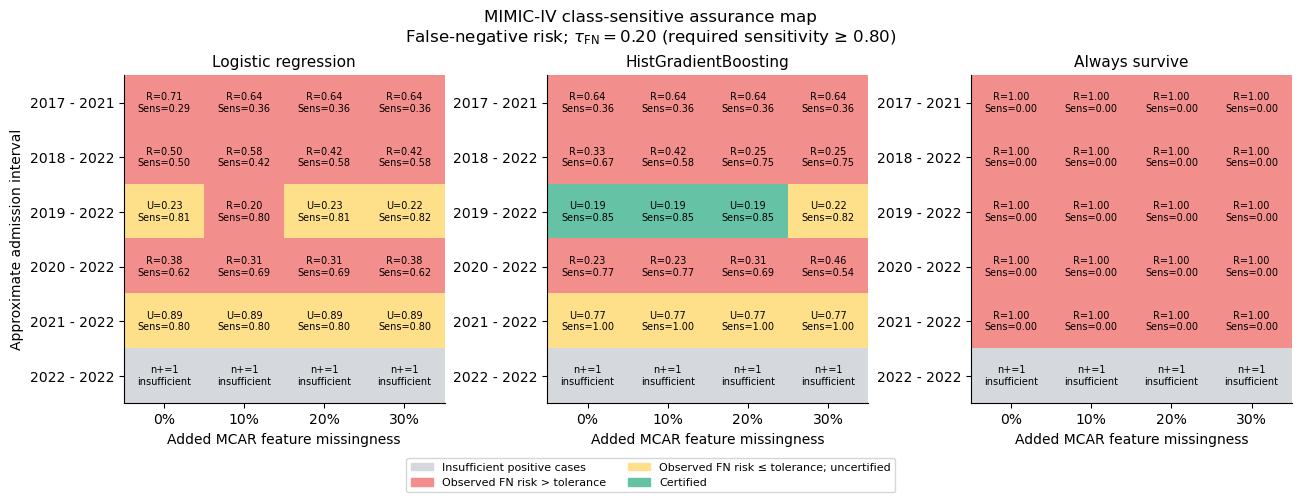


Saved:
C:\Users\maale\OneDrive - University of North Carolina at Charlotte\Desktop\NC A&T State Uni\Research\SciGuard_JMLR_Revision4_Project\results\mimic_local\mimic_class_sensitive_protocol.json
C:\Users\maale\OneDrive - University of North Carolina at Charlotte\Desktop\NC A&T State Uni\Research\SciGuard_JMLR_Revision4_Project\results\mimic_local\mimic_class_sensitive_thresholds.csv
C:\Users\maale\OneDrive - University of North Carolina at Charlotte\Desktop\NC A&T State Uni\Research\SciGuard_JMLR_Revision4_Project\results\mimic_local\mimic_class_sensitive_results.csv
C:\Users\maale\OneDrive - University of North Carolina at Charlotte\Desktop\NC A&T State Uni\Research\SciGuard_JMLR_Revision4_Project\results\mimic_local\mimic_class_sensitive_summary.csv
C:\Users\maale\OneDrive - University of North Carolina at Charlotte\Desktop\NC A&T State Uni\Research\SciGuard_JMLR_Revision4_Project\figures\mimic_class_sensitive\mimic_class_sensitive_sar.png
C:\Users\maale\OneDrive - University of N

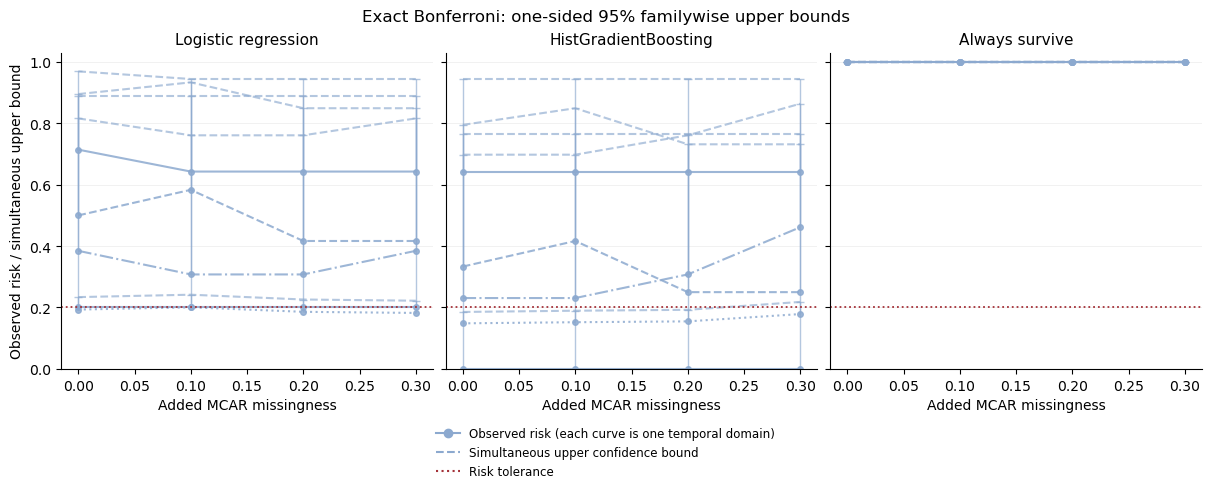

In [75]:
if RUN_MIMIC:
    # ============================================================
    # MIMIC-IV SECONDARY CLASS-SENSITIVE SAR ANALYSIS
    #
    # Reviewer-requested secondary specification:
    #   Loss        = false-negative risk among mortality cases
    #   Requirement = sensitivity >= 80%
    #   tau_FN      = 0.20
    #
    # The learned-model classification thresholds are calibrated
    # ONLY on the independent source holdout and are then frozen
    # before deployment evaluation.
    #
    # Primary inference: exact Clopper-Pearson Bonferroni
    # Secondary check : exact Holm testing
    # ============================================================

    import json
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    from pathlib import Path
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import confusion_matrix
    from scipy.stats import binom

    from sciguard.mimic import (
        load_cohort,
        build_model,
        FEATURES,
    )

    from sciguard.groups import certify_overlapping_groups
    from sciguard.baselines import holm_reject


    # ------------------------------------------------------------
    # 1. FREEZE THE SECONDARY SPECIFICATION BEFORE COMPUTING
    #    THE NEW DEPLOYMENT CERTIFICATES
    # ------------------------------------------------------------

    TAU_FN = 0.20
    TARGET_SOURCE_SENSITIVITY = 0.80
    ALPHA_FN = 0.05

    # Exact inference remains valid in sparse-event settings.
    # The implementation requires at least 2 positive cases
    # for a group to be marked eligible.
    MIN_POSITIVE_COUNT = 2

    FN_RESULTS_DIR = ROOT / "results" / "mimic_local"
    FN_FIG_DIR = ROOT / "figures" / "mimic_class_sensitive"

    FN_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    FN_FIG_DIR.mkdir(parents=True, exist_ok=True)

    secondary_protocol = {
        "analysis": "reviewer_requested_secondary_class_sensitive_MIMIC_IV",
        "dataset": "MIMIC-IV v3.1",
        "loss": "false_negative_risk_conditional_on_Y_equals_1",
        "tau_fn": TAU_FN,
        "tau_interpretation": (
            "Maximum tolerable false-negative risk of 0.20, "
            "equivalent to a deployment sensitivity requirement of at least 0.80."
        ),
        "source_threshold_target_sensitivity": TARGET_SOURCE_SENSITIVITY,
        "threshold_rule": (
            "For each learned model, choose the largest classification threshold "
            "on the independent source holdout that attains sensitivity >= 0.80. "
            "Freeze that threshold before deployment evaluation."
        ),
        "primary_inference": "exact_Clopper_Pearson_Bonferroni",
        "secondary_inference": "exact_Holm",
        "alpha": ALPHA_FN,
        "minimum_positive_count_for_eligibility": MIN_POSITIVE_COUNT,
        "seed": int(MIMIC_CONFIG["seed"]),
        "note": (
            "This is a reviewer-requested secondary analysis added after the "
            "primary MIMIC analysis. The secondary loss, tolerance, and threshold "
            "calibration rule are fixed before recomputing the class-sensitive "
            "deployment certificates. The 80% sensitivity target is an operational "
            "analysis requirement and is not claimed to be a clinical standard."
        ),
    }

    SECONDARY_PROTOCOL_PATH = (
        FN_RESULTS_DIR / "mimic_class_sensitive_protocol.json"
    )

    SECONDARY_PROTOCOL_PATH.write_text(
        json.dumps(secondary_protocol, indent=2)
    )

    print("Secondary protocol frozen at:")
    print(SECONDARY_PROTOCOL_PATH)

    print("\nFalse-negative tolerance:", TAU_FN)
    print(
        "Equivalent sensitivity requirement:",
        1 - TAU_FN
    )


    # ------------------------------------------------------------
    # 2. LOAD THE SAME PRESPECIFIED MIMIC COHORT
    # ------------------------------------------------------------

    mimic_df, _, _ = load_cohort(
        MIMIC_ROOT,
        MIMIC_CONFIG
    )

    source = mimic_df[
        mimic_df["split"] == "source"
    ].copy()

    target = mimic_df[
        mimic_df["split"] == "deployment"
    ].copy()

    train, source_holdout = train_test_split(
        source,
        test_size=0.20,
        stratify=source["mortality"],
        random_state=MIMIC_CONFIG["seed"],
    )

    # Safety checks
    assert set(train["subject_id"]).isdisjoint(
        set(source_holdout["subject_id"])
    )

    assert set(source["subject_id"]).isdisjoint(
        set(target["subject_id"])
    )

    print("\nCohort sizes")
    print("------------")
    print("Training:", len(train))
    print("Source holdout:", len(source_holdout))
    print("Deployment:", len(target))

    print(
        "Source-holdout deaths:",
        int(source_holdout["mortality"].sum())
    )

    print(
        "Deployment deaths:",
        int(target["mortality"].sum())
    )


    # ------------------------------------------------------------
    # 3. HELPER:
    #    largest threshold giving >= target sensitivity
    # ------------------------------------------------------------

    def threshold_for_target_sensitivity(
        probabilities,
        labels,
        target_sensitivity=0.80,
    ):
        probabilities = np.asarray(probabilities, dtype=float)
        labels = np.asarray(labels, dtype=int)

        positive_scores = probabilities[labels == 1]

        if len(positive_scores) == 0:
            raise ValueError(
                "No positive outcomes in source holdout."
            )

        candidates = np.unique(positive_scores)

        sensitivities = np.array([
            np.mean(positive_scores >= threshold)
            for threshold in candidates
        ])

        valid = sensitivities >= target_sensitivity

        if not np.any(valid):
            raise ValueError(
                "Unable to attain requested source sensitivity."
            )

        # Largest threshold satisfying the target.
        # This gives the most specific classifier among thresholds
        # that still meet the source sensitivity requirement.
        threshold = candidates[valid][-1]

        achieved_sensitivity = np.mean(
            positive_scores >= threshold
        )

        return float(threshold), float(achieved_sensitivity)


    # ------------------------------------------------------------
    # 4. DEFINE REAL DEPLOYMENT DOMAINS
    # ------------------------------------------------------------

    domains = sorted(
        target["TemporalDomain"].unique()
    )

    domain_matrix = np.column_stack([
        target["TemporalDomain"]
        .eq(domain)
        .to_numpy()
        for domain in domains
    ])

    y_target = (
        target["mortality"]
        .to_numpy(dtype=int)
    )

    X_target = (
        target[FEATURES]
        .reset_index(drop=True)
    )

    # Conditional groups:
    # domain AND actual mortality Y=1
    positive_indicator = (
        y_target == 1
    ).astype(float)

    positive_group_matrix = (
        domain_matrix
        * positive_indicator[:, None]
    )

    print("\nPositive cases by deployment domain")
    print("-----------------------------------")

    positive_counts_by_domain = (
        positive_group_matrix.sum(axis=0).astype(int)
    )

    for domain, n_positive in zip(
        domains,
        positive_counts_by_domain
    ):
        print(
            f"{domain}: {n_positive} mortality cases"
        )


    # ------------------------------------------------------------
    # 5. USE EXACTLY THE SAME ADDED-MISSINGNESS CONSTRUCTION
    #    AS THE PRIMARY MIMIC ANALYSIS
    # ------------------------------------------------------------

    rng = np.random.default_rng(
        MIMIC_CONFIG["seed"]
    )

    uniforms = rng.random(
        X_target.shape
    )

    # age_topcoded is provenance, not a measured feature;
    # preserve it exactly as in run_mimic().
    uniforms[
        :,
        FEATURES.index("age_topcoded")
    ] = 1.0


    # ------------------------------------------------------------
    # 6. FIT MODELS AND CALIBRATE CLASSIFICATION THRESHOLDS
    #    USING ONLY THE SOURCE HOLDOUT
    # ------------------------------------------------------------

    model_names = (
        list(MIMIC_CONFIG["models"])
        + ["Always survive"]
    )

    threshold_rows = []

    # Each column will contain:
    # I(prediction == 0)
    #
    # The positive-group matrix then conditions this loss on Y=1.
    fn_loss_columns = []
    column_meta = []

    for model_name in model_names:

        if model_name == "Always survive":

            model = None
            threshold = np.nan

            source_sensitivity = 0.0
            source_specificity = 1.0

            print(
                "\nAlways survive:"
                " sensitivity = 0 by construction"
            )

        else:

            model = build_model(
                model_name,
                MIMIC_CONFIG["seed"],
            )

            model.fit(
                train[FEATURES],
                train["mortality"],
            )

            source_prob = model.predict_proba(
                source_holdout[FEATURES]
            )[:, 1]

            threshold, source_sensitivity = (
                threshold_for_target_sensitivity(
                    source_prob,
                    source_holdout["mortality"],
                    TARGET_SOURCE_SENSITIVITY,
                )
            )

            source_pred = (
                source_prob >= threshold
            ).astype(int)

            tn, fp, fn, tp = confusion_matrix(
                source_holdout["mortality"],
                source_pred,
                labels=[0, 1],
            ).ravel()

            source_specificity = (
                tn / (tn + fp)
                if (tn + fp) > 0
                else np.nan
            )

            print(
                f"\n{model_name}"
            )

            print(
                "  calibrated threshold:",
                round(threshold, 6)
            )

            print(
                "  source sensitivity:",
                round(source_sensitivity, 4)
            )

            print(
                "  source specificity:",
                round(source_specificity, 4)
            )

        threshold_rows.append({
            "Model": model_name,
            "TargetSourceSensitivity":
                TARGET_SOURCE_SENSITIVITY,
            "FrozenThreshold": threshold,
            "AchievedSourceSensitivity":
                source_sensitivity,
            "SourceSpecificity":
                source_specificity,
        })


        # --------------------------------------------------------
        # Evaluate the frozen pipeline under deployment
        # missingness conditions
        # --------------------------------------------------------

        for missingness in MIMIC_CONFIG[
            "missingness_levels"
        ]:

            X_missing = X_target.mask(
                uniforms < missingness
            )

            if model is None:

                # Always-survive predicts 0 for everybody.
                pred = np.zeros(
                    len(y_target),
                    dtype=int,
                )

            else:

                deployment_prob = (
                    model.predict_proba(
                        X_missing
                    )[:, 1]
                )

                pred = (
                    deployment_prob >= threshold
                ).astype(int)

            # False-negative loss indicator.
            #
            # This is defined for all rows; the positive group
            # matrix restricts estimation to actual deaths.
            fn_loss = (
                pred == 0
            ).astype(float)

            fn_loss_columns.append(
                fn_loss
            )

            column_meta.append(
                (
                    model_name,
                    float(missingness),
                )
            )


    threshold_table = pd.DataFrame(
        threshold_rows
    )

    fn_losses = np.column_stack(
        fn_loss_columns
    )

    print(
        "\nFalse-negative loss matrix:",
        fn_losses.shape
    )


    # ------------------------------------------------------------
    # 7. PRIMARY INFERENCE:
    #    EXACT CLOPPER-PEARSON + BONFERRONI
    #
    # This is deliberately primary because the outcome is binary
    # and positive-event counts are much smaller than total n.
    # ------------------------------------------------------------

    exact_result = certify_overlapping_groups(
        fn_losses,
        positive_group_matrix,
        tau=TAU_FN,
        alpha=ALPHA_FN,
        B=MIMIC_CONFIG["bootstrap_draws"],
        seed=MIMIC_CONFIG["seed"] + 8001,
        min_group_size=MIN_POSITIVE_COUNT,
        method="exact_bonferroni",
    )


    # ------------------------------------------------------------
    # 8. SECONDARY EXACT HOLM TEST
    # ------------------------------------------------------------

    positive_sizes = np.repeat(
        positive_group_matrix.sum(axis=0),
        len(column_meta),
    ).astype(int)

    fn_counts = (
        positive_group_matrix.T
        @ fn_losses
    ).ravel().astype(int)

    holm_eligible = (
        positive_sizes
        >= MIN_POSITIVE_COUNT
    )

    holm_pvalues = np.ones(
        len(positive_sizes),
        dtype=float,
    )

    holm_pvalues[
        holm_eligible
    ] = binom.cdf(
        fn_counts[holm_eligible],
        positive_sizes[holm_eligible],
        TAU_FN,
    )

    holm_certified = (
        holm_reject(
            holm_pvalues,
            ALPHA_FN,
        )
        & holm_eligible
    )


    # ------------------------------------------------------------
    # 9. BUILD LONG-FORM RESULT TABLE
    # ------------------------------------------------------------

    rows = []

    n_columns = len(column_meta)

    for i, domain in enumerate(domains):

        for j, (
            model_name,
            missingness,
        ) in enumerate(column_meta):

            k = (
                i * n_columns
                + j
            )

            n_pos = int(
                positive_sizes[k]
            )

            n_fn = int(
                fn_counts[k]
            )

            risk = (
                n_fn / n_pos
                if n_pos > 0
                else np.nan
            )

            sensitivity = (
                1 - risk
                if np.isfinite(risk)
                else np.nan
            )

            # Exact Bonferroni result
            rows.append({
                "TemporalDomain": domain,
                "Model": model_name,
                "Missingness": missingness,
                "method": "exact_bonferroni",
                "positive_n": n_pos,
                "false_negatives": n_fn,
                "fn_risk": risk,
                "sensitivity": sensitivity,
                "upper_fn_risk":
                    exact_result.upper[k],
                "certified":
                    bool(exact_result.certified[k]),
                "eligible":
                    bool(exact_result.eligible[k]),
                "tau_fn": TAU_FN,
                "required_sensitivity":
                    1 - TAU_FN,
                "alpha": ALPHA_FN,
            })

            # Holm result
            rows.append({
                "TemporalDomain": domain,
                "Model": model_name,
                "Missingness": missingness,
                "method": "holm",
                "positive_n": n_pos,
                "false_negatives": n_fn,
                "fn_risk": risk,
                "sensitivity": sensitivity,
                "upper_fn_risk": np.nan,
                "certified":
                    bool(holm_certified[k]),
                "eligible":
                    bool(holm_eligible[k]),
                "tau_fn": TAU_FN,
                "required_sensitivity":
                    1 - TAU_FN,
                "alpha": ALPHA_FN,
            })


    class_sensitive_results = pd.DataFrame(
        rows
    )


    # ------------------------------------------------------------
    # 10. SAVE ALL RESULTS
    # ------------------------------------------------------------

    threshold_table.to_csv(
        FN_RESULTS_DIR
        / "mimic_class_sensitive_thresholds.csv",
        index=False,
    )

    class_sensitive_results.to_csv(
        FN_RESULTS_DIR
        / "mimic_class_sensitive_results.csv",
        index=False,
    )


    # ------------------------------------------------------------
    # 11. DISPLAY THE IMPORTANT TABLES
    # ------------------------------------------------------------

    print(
        "\n===================================================="
    )
    print(
        "SOURCE-HOLDOUT THRESHOLD CALIBRATION"
    )
    print(
        "===================================================="
    )

    display(
        threshold_table.round(4)
    )


    exact_table = (
        class_sensitive_results[
            class_sensitive_results[
                "method"
            ] == "exact_bonferroni"
        ]
        .copy()
    )

    print(
        "\n===================================================="
    )
    print(
        "MIMIC-IV CLASS-SENSITIVE SAR RESULTS"
    )
    print(
        "Primary method: exact Clopper-Pearson Bonferroni"
    )
    print(
        "===================================================="
    )

    display(
        exact_table.round(4)
    )


    # ------------------------------------------------------------
    # 12. COMPACT SUMMARY FOR THE MANUSCRIPT
    # ------------------------------------------------------------

    summary = (
        exact_table
        .groupby(
            ["Model", "Missingness"],
            as_index=False,
        )
        .agg(
            eligible_environments=(
                "eligible",
                "sum",
            ),
            certified_environments=(
                "certified",
                "sum",
            ),
            min_sensitivity=(
                "sensitivity",
                "min",
            ),
            max_sensitivity=(
                "sensitivity",
                "max",
            ),
            max_upper_fn_risk=(
                "upper_fn_risk",
                "max",
            ),
            min_positive_n=(
                "positive_n",
                "min",
            ),
        )
    )

    summary[
        "certified_fraction"
    ] = np.where(
        summary[
            "eligible_environments"
        ] > 0,
        summary[
            "certified_environments"
        ]
        / summary[
            "eligible_environments"
        ],
        np.nan,
    )

    summary.to_csv(
        FN_RESULTS_DIR
        / "mimic_class_sensitive_summary.csv",
        index=False,
    )

    print(
        "\n===================================================="
    )
    print(
        "COMPACT MANUSCRIPT SUMMARY"
    )
    print(
        "===================================================="
    )

    display(
        summary.round(4)
    )


    # ------------------------------------------------------------
    # 13. OVERALL COUNTS
    # ------------------------------------------------------------

    eligible_exact = exact_table[
        exact_table["eligible"]
    ]

    print(
        "\n===================================================="
    )
    print(
        "SECONDARY MIMIC-IV KEY NUMBERS"
    )
    print(
        "===================================================="
    )

    print(
        "Total exact-family conditions:",
        len(exact_table),
    )

    print(
        "Eligible conditions:",
        int(
            exact_table[
                "eligible"
            ].sum()
        ),
    )

    print(
        "Certified conditions:",
        int(
            exact_table[
                "certified"
            ].sum()
        ),
    )

    if len(eligible_exact) > 0:

        print(
            "Minimum observed sensitivity:",
            round(
                eligible_exact[
                    "sensitivity"
                ].min(),
                4,
            ),
        )

        print(
            "Maximum observed sensitivity:",
            round(
                eligible_exact[
                    "sensitivity"
                ].max(),
                4,
            ),
        )

        print(
            "Maximum exact upper FN risk:",
            round(
                eligible_exact[
                    "upper_fn_risk"
                ].max(),
                4,
            ),
        )


    # ------------------------------------------------------------
    # 14. CLASS-SENSITIVE ASSURANCE MAP
    # ------------------------------------------------------------

    from matplotlib.colors import ListedColormap
    from matplotlib.patches import Patch

    plot_data = exact_table.copy()

    plot_models = list(
        dict.fromkeys(
            plot_data["Model"]
        )
    )

    plot_domains = sorted(
        plot_data[
            "TemporalDomain"
        ].unique()
    )

    plot_levels = sorted(
        plot_data[
            "Missingness"
        ].unique()
    )

    fig, axes = plt.subplots(
        1,
        len(plot_models),
        figsize=(
            4.3 * len(plot_models),
            max(
                4.8,
                0.48 * len(plot_domains) + 2,
            ),
        ),
        squeeze=False,
        layout="constrained",
    )

    # gray / red / yellow / green
    cmap = ListedColormap([
        REGION_COLORS["insufficient"],
        REGION_COLORS["uncertified"],
        REGION_COLORS["borderline"],
        REGION_COLORS["safe"],
    ])

    for ax, model_name in zip(
        axes[0],
        plot_models,
    ):

        states = np.zeros(
            (
                len(plot_domains),
                len(plot_levels),
            )
        )

        annotations = np.empty(
            states.shape,
            dtype=object,
        )

        for i, domain in enumerate(
            plot_domains
        ):

            for j, missingness in enumerate(
                plot_levels
            ):

                row = plot_data[
                    (
                        plot_data[
                            "Model"
                        ] == model_name
                    )
                    & (
                        plot_data[
                            "TemporalDomain"
                        ] == domain
                    )
                    & np.isclose(
                        plot_data[
                            "Missingness"
                        ],
                        missingness,
                    )
                ].iloc[0]

                if not row["eligible"]:

                    states[i, j] = 0

                    annotations[
                        i, j
                    ] = (
                        f"n+={int(row['positive_n'])}"
                        "\ninsufficient"
                    )

                elif row["certified"]:

                    states[i, j] = 3

                    annotations[
                        i, j
                    ] = (
                        f"U={row['upper_fn_risk']:.2f}"
                        f"\nSens={row['sensitivity']:.2f}"
                    )

                elif (
                    row["fn_risk"]
                    <= TAU_FN
                ):

                    states[i, j] = 2

                    annotations[
                        i, j
                    ] = (
                        f"U={row['upper_fn_risk']:.2f}"
                        f"\nSens={row['sensitivity']:.2f}"
                    )

                else:

                    states[i, j] = 1

                    annotations[
                        i, j
                    ] = (
                        f"R={row['fn_risk']:.2f}"
                        f"\nSens={row['sensitivity']:.2f}"
                    )

        ax.imshow(
            states,
            cmap=cmap,
            vmin=0,
            vmax=3,
            aspect="auto",
        )

        ax.set_xticks(
            range(
                len(plot_levels)
            )
        )

        ax.set_xticklabels([
            f"{m:.0%}"
            for m in plot_levels
        ])

        ax.set_yticks(
            range(
                len(plot_domains)
            )
        )

        ax.set_yticklabels(
            plot_domains
        )

        ax.set_xlabel(
            "Added MCAR feature missingness"
        )

        ax.set_title(
            model_name
        )

        for i, j in np.ndindex(
            states.shape
        ):

            ax.text(
                j,
                i,
                annotations[i, j],
                ha="center",
                va="center",
                fontsize=7,
            )


    axes[
        0, 0
    ].set_ylabel(
        "Approximate admission interval"
    )

    fig.suptitle(
        "MIMIC-IV class-sensitive assurance map\n"
        "False-negative risk; "
        r"$\tau_{\mathrm{FN}}=0.20$ "
        "(required sensitivity ≥ 0.80)"
    )

    fig.legend(
        handles=[
            Patch(
                color=cmap.colors[0],
                label="Insufficient positive cases",
            ),
            Patch(
                color=cmap.colors[1],
                label="Observed FN risk > tolerance",
            ),
            Patch(
                color=cmap.colors[2],
                label="Observed FN risk ≤ tolerance; uncertified",
            ),
            Patch(
                color=cmap.colors[3],
                label="Certified",
            ),
        ],
        loc="outside lower center",
        ncol=2,
        fontsize=8,
    )

    FIG_PNG = (
        FN_FIG_DIR
        / "mimic_class_sensitive_sar.png"
    )

    FIG_PDF = (
        FN_FIG_DIR
        / "mimic_class_sensitive_sar.pdf"
    )

    fig.savefig(
        FIG_PNG,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        FIG_PDF,
        bbox_inches="tight",
    )

    plt.show()


    # ------------------------------------------------------------
    # 15. FINAL FILE LOCATIONS
    # ------------------------------------------------------------

    print(
        "\nSaved:"
    )

    print(
        FN_RESULTS_DIR
        / "mimic_class_sensitive_protocol.json"
    )

    print(
        FN_RESULTS_DIR
        / "mimic_class_sensitive_thresholds.csv"
    )

    print(
        FN_RESULTS_DIR
        / "mimic_class_sensitive_results.csv"
    )

    print(
        FN_RESULTS_DIR
        / "mimic_class_sensitive_summary.csv"
    )

    print(
        FIG_PNG
    )

    print(
        FIG_PDF
    )
    risk_bound_figure(class_sensitive_results, 'fn_risk', 'upper_fn_risk', 'TemporalDomain', 'mimic_fn_upper_bounds', FN_FIG_DIR, TAU_FN)


## 12. Integrity checks, manuscript export, and interpretation
Assertions below check structural consistency and data provenance, not agreement with a
preferred numerical answer. Manuscript tables/macros are generated directly from the
completed full-run CSVs. Bootstrap seed changes can change numerical results; versions and
random seeds are recorded. The `archive/` results are historical and do not feed current tables.

The software checks and synthetic MIMIC fixture test are available through
`python -m unittest discover -s tests -v`. The real MIMIC data path cannot be validated by a
synthetic fixture. The credentialed MIMIC-IV benchmark is reported from its stored aggregate outputs;
re-executing it requires separately obtained credentialed data.

In [77]:
expected_sections = set(SECTIONS)
assert set(run.manifest['sections']) == expected_sections
assert all(v['status'] == 'completed' for v in run.manifest['sections'].values())
assert len(calibration_replications) == CONFIG.calibration_reps * 6
assert len(nested_replications) == CONFIG.nested_reps * 2 * 5
assert len(missingness_replications) == CONFIG.missingness_reps * 4 * 3
assert (nested_replications.containment_lower <= nested_replications.reference_containment).all()
assert (nested_replications.reference_containment <= nested_replications.containment_upper).all()
assert wdbc_summary['n'].eq(200).all()
assert wdbc_detail.upper.dropna().between(0, 1).all()
assert set(wdbc_summary.Model) == {'Logistic regression', 'Extra Trees', 'HistGradientBoosting'}
run.finish()
if PROFILE == 'full':
    completed = subprocess.run([sys.executable, str(ROOT / 'scripts/export_manuscript.py')],
        cwd=ROOT, text=True, capture_output=True, check=True)
    print(completed.stdout.strip())
else:
    print('Smoke output is separate; manuscript tables were not changed.')
display(pd.DataFrame(run.manifest['sections']).T)
print('External benchmark status:', run.manifest['external_benchmark'])
print('Current-run CSV files:', len(run.manifest['output_sha256']))
print('All public/synthetic sections completed. This is not a declaration of submission readiness.')

Exported 13 manuscript inputs from full-run CSVs


,status,seconds
calibration,completed,4.001387
nested,completed,942.457596
missingness,completed,83.866174
wdbc,completed,3.241454
sensitivity,completed,14.719795
bootstrap_and_stress,completed,9.934167
continuous,completed,8.300174
pilot_design,completed,0.785415


External benchmark status: completed_credentialed_data
Current-run CSV files: 30
All public/synthetic sections completed. This is not a declaration of submission readiness.


## 13. Results revision: validity anatomy, power and planning, profiles, and effective sample size
These analyses were added in the October 2026 results revision. They are organized by the
manuscript's four research questions (Table 1): RQ1, is the advertised validity achieved; RQ2, how
much is certified and what determines it; RQ3, what changes across fitted pipelines and
missingness mechanisms; RQ4, what a certificate means in real data. RQ3 is answered by Sections 4
and 5 above; this section adds evidence for RQ1, RQ2, and RQ4.

`scripts/run_revision.py` writes `results/revision/` and `figures/revision/` with a separate
manifest. It reads the original full-run outputs in `results/full/` only after verifying their
SHA-256 hashes and never rewrites them. By default this notebook loads the completed revision
outputs and checks their hashes; set `SCIGUARD_RUN_REVISION=1` to recompute them (about five
minutes, single-threaded). New simulations use new random-number streams; archived seeds are
reused only where an analysis regenerates archived replications.

In [ ]:
from IPython.display import Image
from sciguard.revision import (REVISION_SECTIONS, exact_certification_probability, minimal_assurance_n,
                               minimal_n_zero_errors, zero_error_upper)

RUN_REVISION = os.environ.get('SCIGUARD_RUN_REVISION', '0') == '1'
REVISION_OUT = ROOT / 'results/revision'
REVISION_FIG = ROOT / 'figures/revision'
if RUN_REVISION:
    completed = subprocess.run([sys.executable, str(ROOT / 'scripts/run_revision.py')], cwd=ROOT,
                               text=True, capture_output=True, check=True)
    print(completed.stdout.strip()[-1500:])

def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

revision_manifest = json.loads((REVISION_OUT / 'revision_manifest.json').read_text())
assert revision_manifest['status'] == 'completed'
assert set(REVISION_SECTIONS) <= set(revision_manifest['sections'])
assert all(v['status'] == 'completed' for v in revision_manifest['sections'].values())
changed = [k for k, v in revision_manifest['output_sha256'].items() if file_sha256(REVISION_OUT / k) != v]
assert not changed, changed
full_manifest = json.loads((ROOT / 'results/full/run_manifest.json').read_text())
changed_full = [k for k, v in full_manifest['output_sha256'].items()
                if file_sha256(ROOT / 'results/full' / k) != v]
assert not changed_full, changed_full
R = {p.stem: pd.read_csv(p) for p in sorted(REVISION_OUT.glob('*.csv'))}
display(pd.DataFrame([{'section': k, 'seconds': round(v['seconds'], 1)}
                      for k, v in revision_manifest['sections'].items()]))
print('Revision environment: Python', revision_manifest['python'], '|', revision_manifest['platform'])
print('Verified', len(revision_manifest['output_sha256']), 'revision CSV files; original full-run outputs unchanged.')

,section,seconds
0,power_study,208.8
1,power_planning,26.2
2,continuous_exact,0.2
3,tolerance_profiles,0.1
4,mimic_effective_sample_size,0.3
5,calibration_anatomy,2.2
6,stress_coincidence,1.4
7,studentized_tail,0.0
8,bootstrap_reproduction,1.0


Revision environment: Python 3.14.3 | Linux-6.1.155-x86_64-with-glibc2.43
Verified 15 revision CSV files; original full-run outputs unchanged.


### 13.1 RQ1: validity under known risks
For a full band the validity criterion is simultaneous band coverage; containment at one tolerance
can stay near one when the band fails. The anatomy table regenerates the 500 primary-calibration
replications from their archived seeds and splits band failures into those that missed only truly
safe environments (which cannot create a false certificate) and those that missed an unsafe one.
The coincidence summary explains why Bonferroni normal and the multiplier have identical coverage in
the bounded-continuous and rare-binary designs. The exact tail table computes, from the binomial
distribution and without simulation, how often the studentized normal upper bound fails at level
alpha/K, as a multiple of that nominal level; it explains the undercoverage at large n in large families.

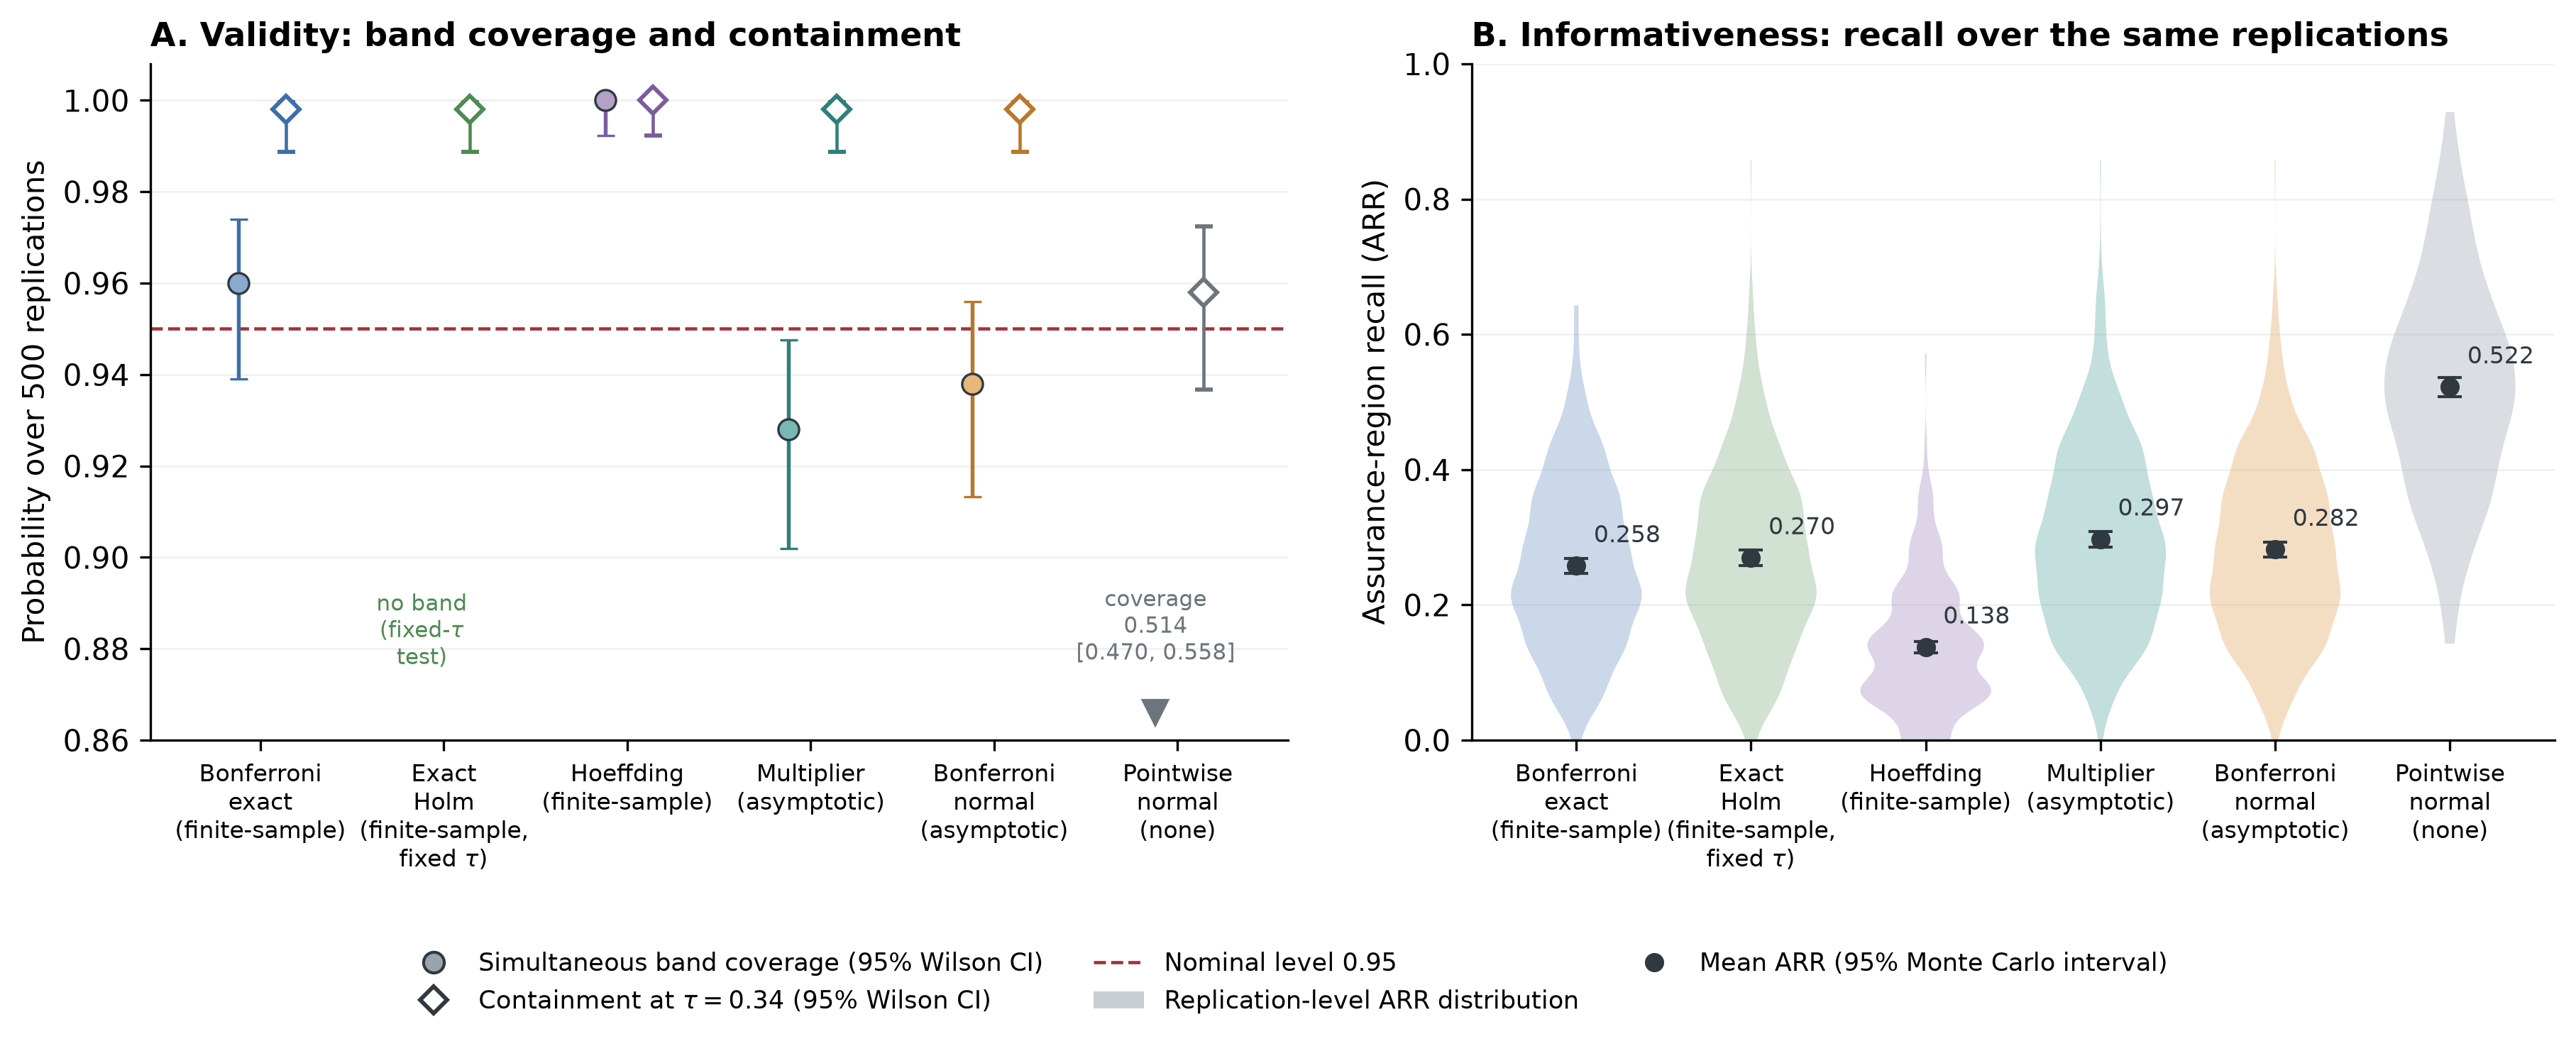

,method,replications,reproduces_original,coverage_failures,failures_safe_only,failures_with_unsafe_miss,failures_with_false_certificate,containment_failures
0,pointwise,500,500,243.0,89.0,154.0,21.0,21
1,normal_bonferroni,500,500,31.0,18.0,13.0,1.0,1
2,multiplier,500,466,34.0,19.0,15.0,1.0,1
3,exact_bonferroni,500,500,20.0,9.0,11.0,1.0,1
4,hoeffding,500,500,0.0,0.0,0.0,0.0,0
5,holm,500,500,NaN,NaN,NaN,NaN,1


,replications,matches_archived_run,identical_coverage,multiplier_critical,bonferroni_critical,multiplier_coverage,bonferroni_normal_coverage
scenario,,,,,,,
bounded_continuous,200,200,200,2.870,2.878,0.925,0.925
rare_binary,200,199,199,2.823,2.878,0.775,0.780


Rare-binary replications with a missed environment: 44; share in which a missed environment had at most 3 observed errors: 61%


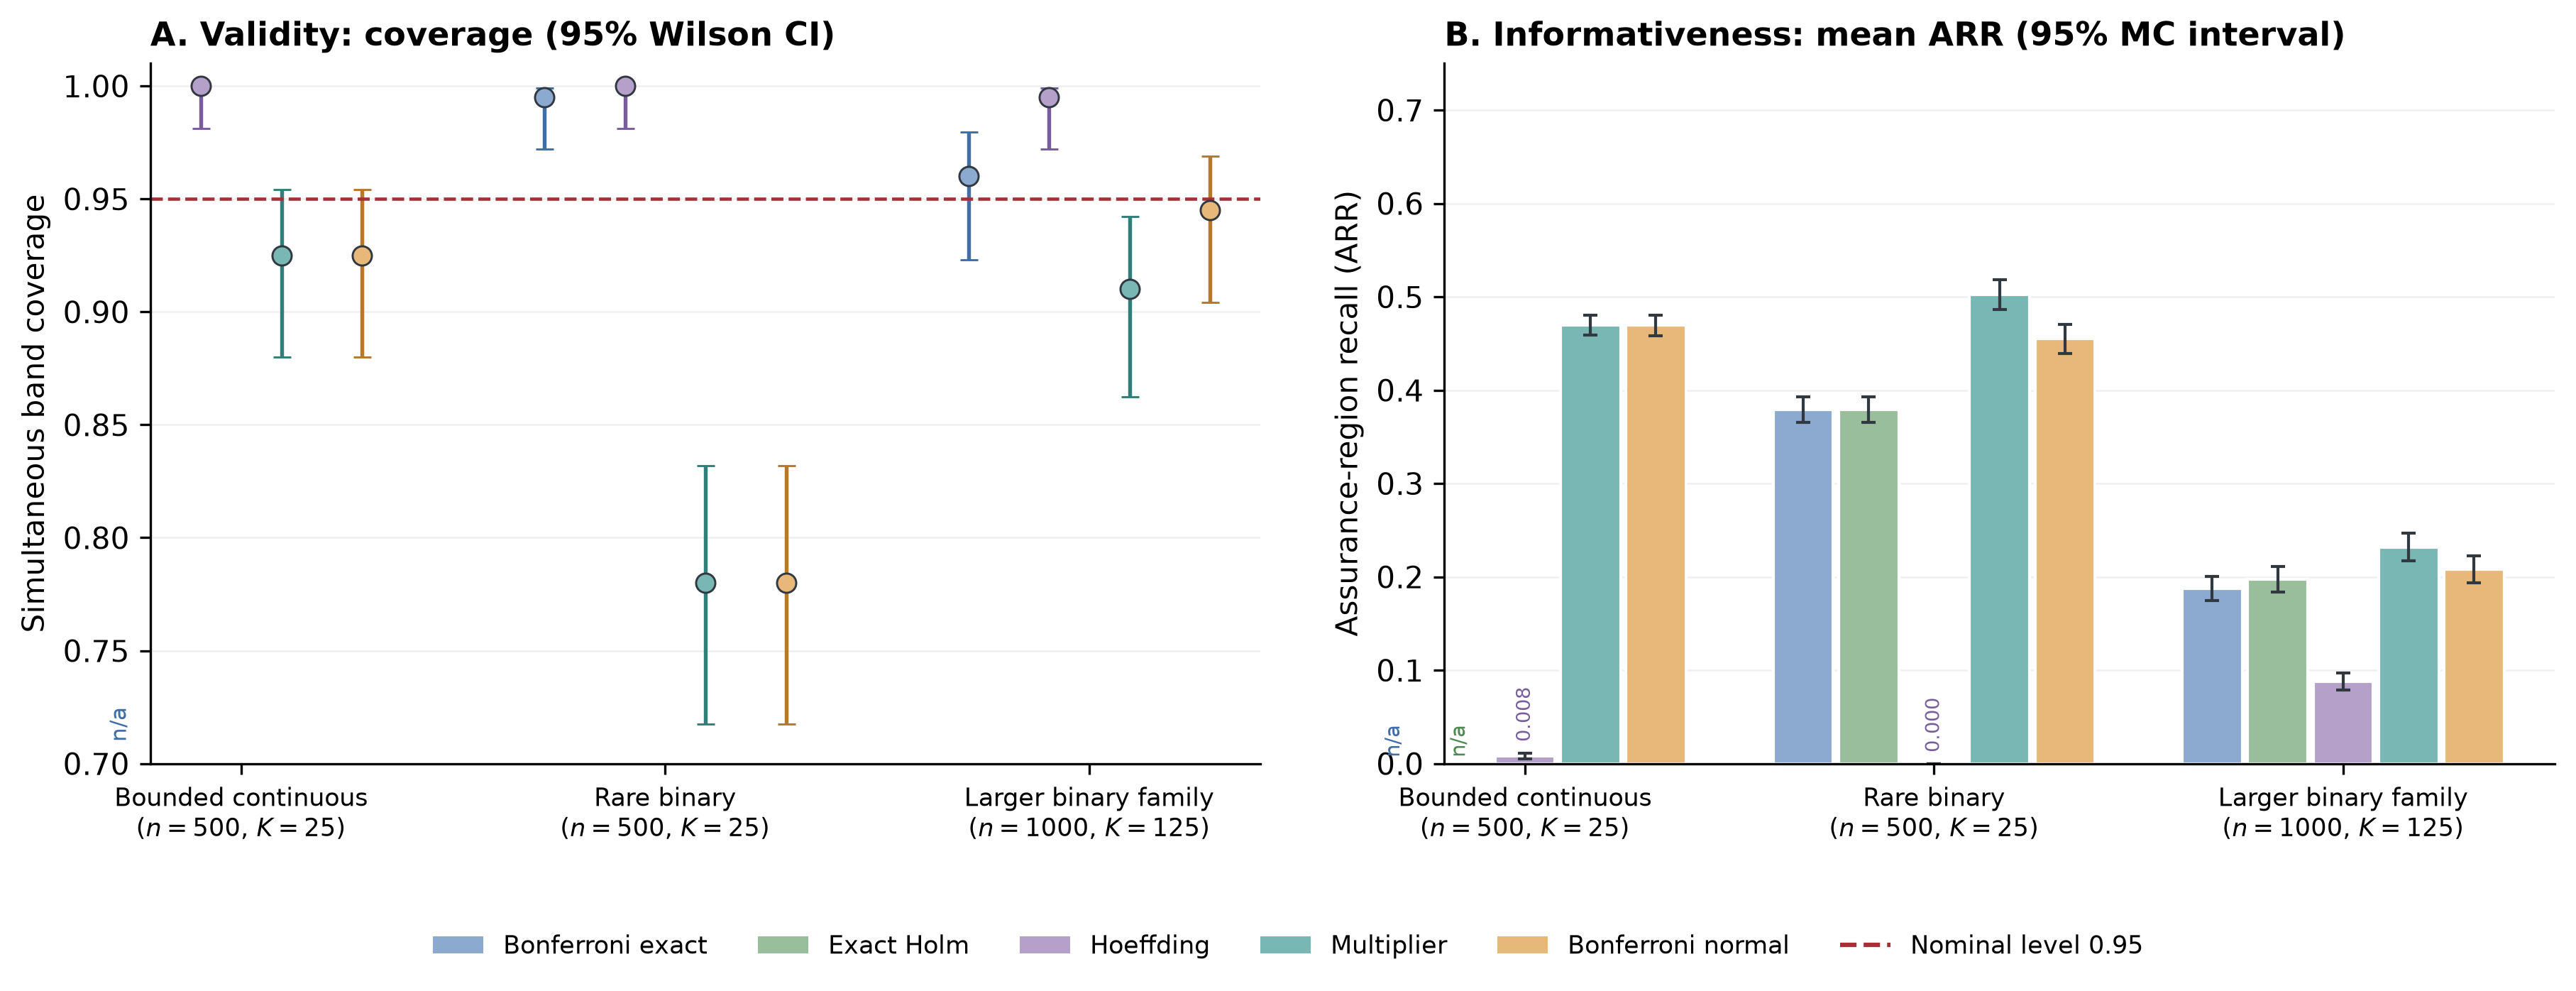

n         250    500    1000   2000   4000   8000   32000
K   risk                                                 
25  0.05   6.54   5.41   2.96   2.29   1.63   1.52   1.24
    0.09   4.55   2.71   2.50   1.81   1.59   1.31   1.19
    0.11   4.65   2.22   1.95   1.52   1.50   1.27   1.16
    0.15   3.98   1.94   1.84   1.38   1.26   1.17   1.13
100 0.05  26.17  11.02   4.39   3.23   2.45   1.80   1.36
    0.09   8.60   6.42   3.29   2.53   1.72   1.61   1.20
    0.11   9.60   3.29   2.79   2.32   1.83   1.53   1.24
    0.15   4.90   3.31   2.23   1.92   1.53   1.31   1.15
500 0.05  45.71  26.10   7.19   5.06   3.12   2.33   1.60
    0.09  18.63  10.10   4.70   2.90   2.47   1.85   1.38
    0.11  10.47   9.61   4.46   3.06   2.01   1.75   1.33
    0.15  12.69   6.52   2.92   2.34   1.70   1.60   1.25

sd_difference  same_certified  seeds
n    K   B                                         
500  25  200           0.114              11     25
         1000          0.047              19     25
         5000          0.025              20     25
1000 25  200           0.173              11     25
         1000          0.066              19     25
         5000          0.021              24     25
     125 200           0.057              15     25
         1000          0.027              20     25
         5000          0.014              22     25

In [ ]:
display(Image(filename=str(REVISION_FIG / 'calibration_validity.png'), width=900))
display(R['calibration_anatomy_summary'])

stress = R['stress_coincidence'].assign(
    identical=lambda d: d.coverage_multiplier == d.coverage_normal_bonferroni)
display(stress.groupby('scenario').agg(
    replications=('rep', 'size'), matches_archived_run=('matches_archive', 'sum'),
    identical_coverage=('identical', 'sum'),
    multiplier_critical=('multiplier_critical', 'mean'), bonferroni_critical=('bonferroni_critical', 'mean'),
    multiplier_coverage=('coverage_multiplier', 'mean'),
    bonferroni_normal_coverage=('coverage_normal_bonferroni', 'mean')).round(3))
rare = stress[(stress.scenario == 'rare_binary') & stress.min_errors_in_missed.notna()]
print(f'Rare-binary replications with a missed environment: {len(rare)}; '
      f'share in which a missed environment had at most 3 observed errors: {(rare.min_errors_in_missed <= 3).mean():.0%}')
display(Image(filename=str(REVISION_FIG / 'stress_validity.png'), width=900))

tail = R['studentized_tail_inflation']
display(tail.pivot_table(index=['K', 'risk'], columns='n', values='inflation').round(2))

boot = R['bootstrap_reproduction']
display(boot.groupby(['n', 'K', 'B']).agg(
    sd_difference=('difference', 'std'),
    same_certified=('archived_certified', lambda s: int((s == boot.loc[s.index, 'recomputed_certified']).sum())),
    seeds=('rep', 'size')).round(3))

### 13.2 RQ2: risk margin, sample size, and exact planning
Half of the K environments have risk tau - Delta and half tau + Delta (tau = .10). For exact
Clopper-Pearson Bonferroni the certification probability of an environment with risk R has the
closed form P_cert(n, R) = P{Bin(n, R) <= s*}, where s* is the largest error count whose exact upper
bound at level alpha/K is at most tau (equation 9 of the manuscript). The check below compares the
simulated exact-Bonferroni recall with this closed form in every cell. The planning table reports the
smallest n from which the certification probability stays at or above 0.8 or 0.9, next to the
Hoeffding width rule.

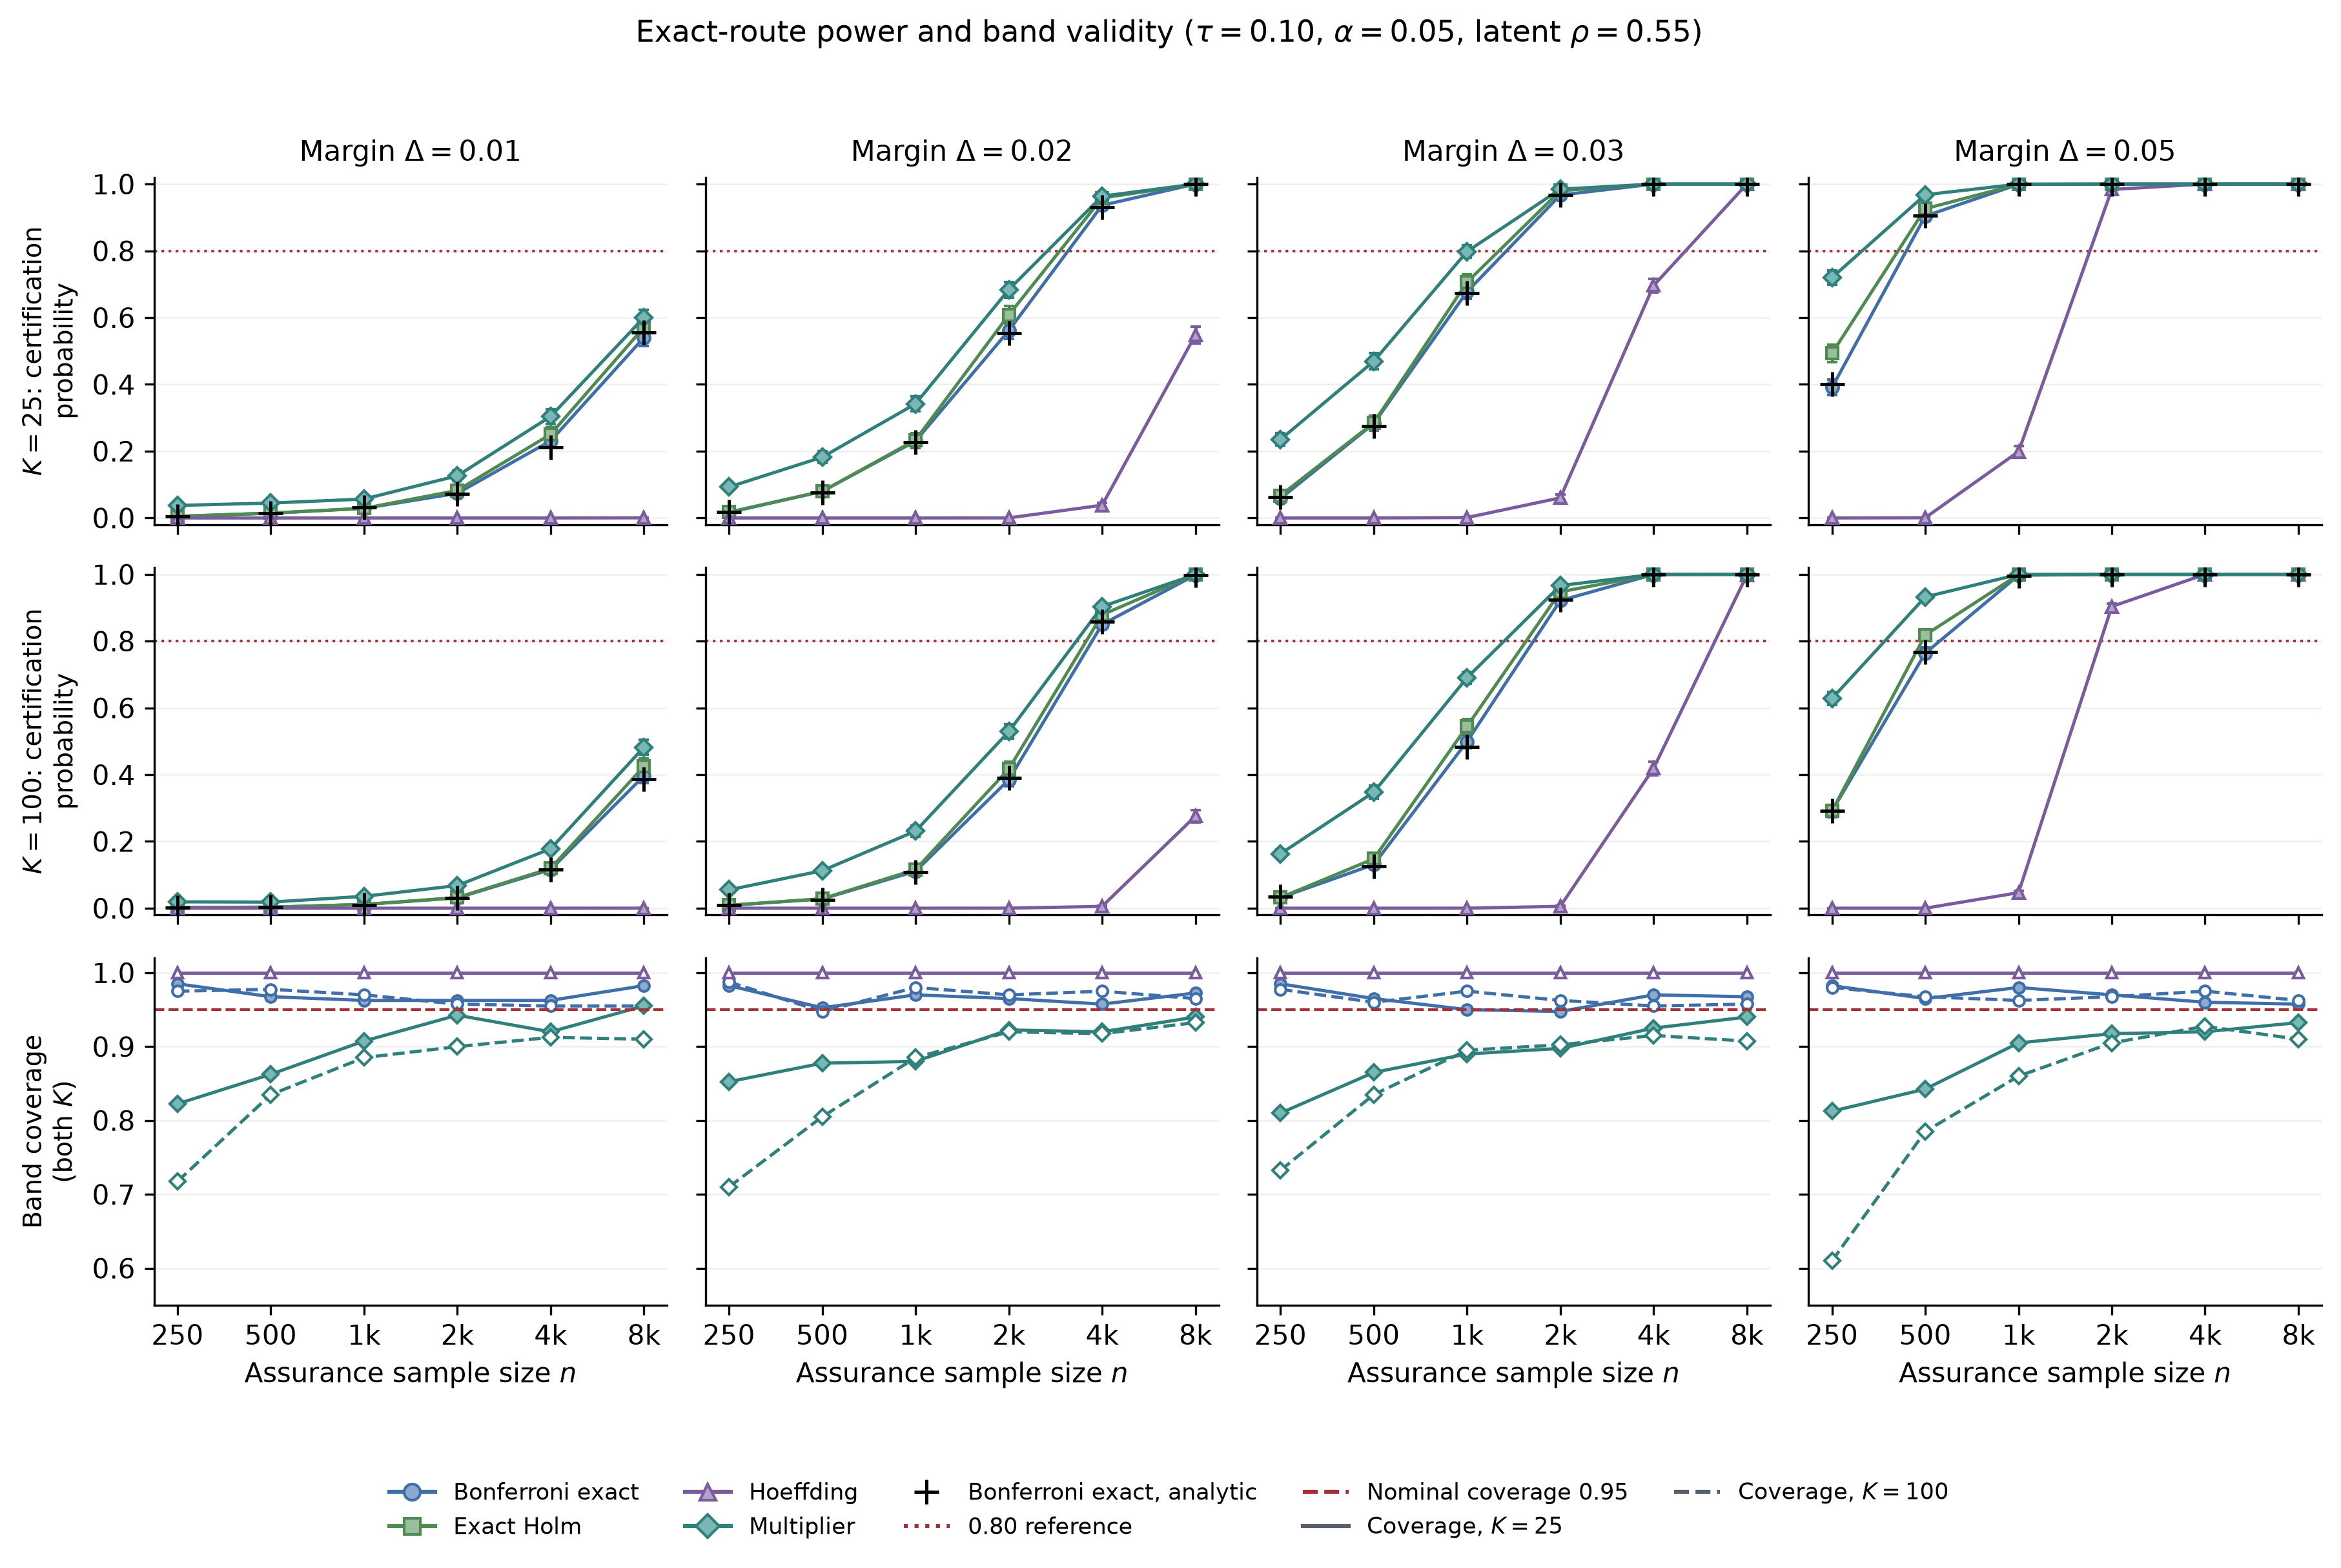

Largest |simulated exact recall - closed form|: 0.0185


method    exact_bonferroni  hoeffding  multiplier
K   n                                            
25  250              0.982        1.0       0.810
    500              0.952        1.0       0.842
    1000             0.950        1.0       0.880
    2000             0.948        1.0       0.898
    4000             0.958        1.0       0.920
    8000             0.958        1.0       0.932
100 250              0.975        1.0       0.610
    500              0.948        1.0       0.785
    1000             0.962        1.0       0.860
    2000             0.958        1.0       0.900
    4000             0.955        1.0       0.912
    8000             0.955        1.0       0.908

,tau,K,delta,alpha,hoeffding_width_n,exact_n_80_first,exact_n_80,exact_n_90_first,exact_n_90,exact_probability_at_hoeffding_n,hoeffding_probability_at_hoeffding_n
0,0.1,25,0.01,0.05,31074,12012,12179,14972,15138,0.999111,0.499816
1,0.1,25,0.02,0.05,7769,2890,2966,3582,3668,0.999496,0.502003
2,0.1,25,0.03,0.05,3453,1228,1285,1522,1567,0.999753,0.498228
3,0.1,25,0.05,0.05,1243,397,422,485,522,0.999960,0.525932
4,0.1,100,0.01,0.05,38005,14824,14991,18100,18277,0.999590,0.501335
5,0.1,100,0.02,0.05,9502,3561,3648,4343,4418,0.999775,0.507241
6,0.1,100,0.03,0.05,4223,1516,1573,1846,1891,0.999887,0.500804
7,0.1,100,0.05,0.05,1521,503,528,591,616,0.999989,0.528122
8,0.1,500,0.01,0.05,46052,18057,18235,21660,21837,0.999832,0.499719
9,0.1,500,0.02,0.05,11513,4343,4431,5192,5279,0.999917,0.508222


K=25, risk .05, tau .10: certification probability first reaches 0.8 at n=397 and stays at or above 0.8 from n=422.


In [ ]:
display(Image(filename=str(REVISION_FIG / 'power.png'), width=900))
summary = R['power_summary']; analytic = R['power_analytic']
exact = summary[summary.method == 'exact_bonferroni'].merge(analytic, on=['K', 'n', 'delta'])
print('Largest |simulated exact recall - closed form|:',
      round(float((exact.ARR - exact.exact_certification_probability).abs().max()), 4))
display(summary.pivot_table(index=['K', 'n'], columns='method', values='simultaneous_coverage',
                            aggfunc='min').round(3))
display(R['power_planning'])
first, stable = minimal_assurance_n(.05, .10, .05, 25, .80)
print(f'K=25, risk .05, tau .10: certification probability first reaches 0.8 at n={first} '
      f'and stays at or above 0.8 from n={stable}.')

### 13.3 RQ2 and RQ4: exact continuous example, tolerance-certification profiles, and MIMIC effective sample size
Because a full simultaneous band covers every tolerance at once, the profile of the certified
fraction against tau is covered by the same 1 - alpha statement; it is descriptive sensitivity, not a
device for choosing a tolerance. For the MIMIC false-negative specification the effective sample size
of a domain is its number of deaths: with K = 72 and alpha = .05, zero false negatives among n+ deaths
gives the smallest attainable upper bound 1 - (alpha/K)^(1/n+).

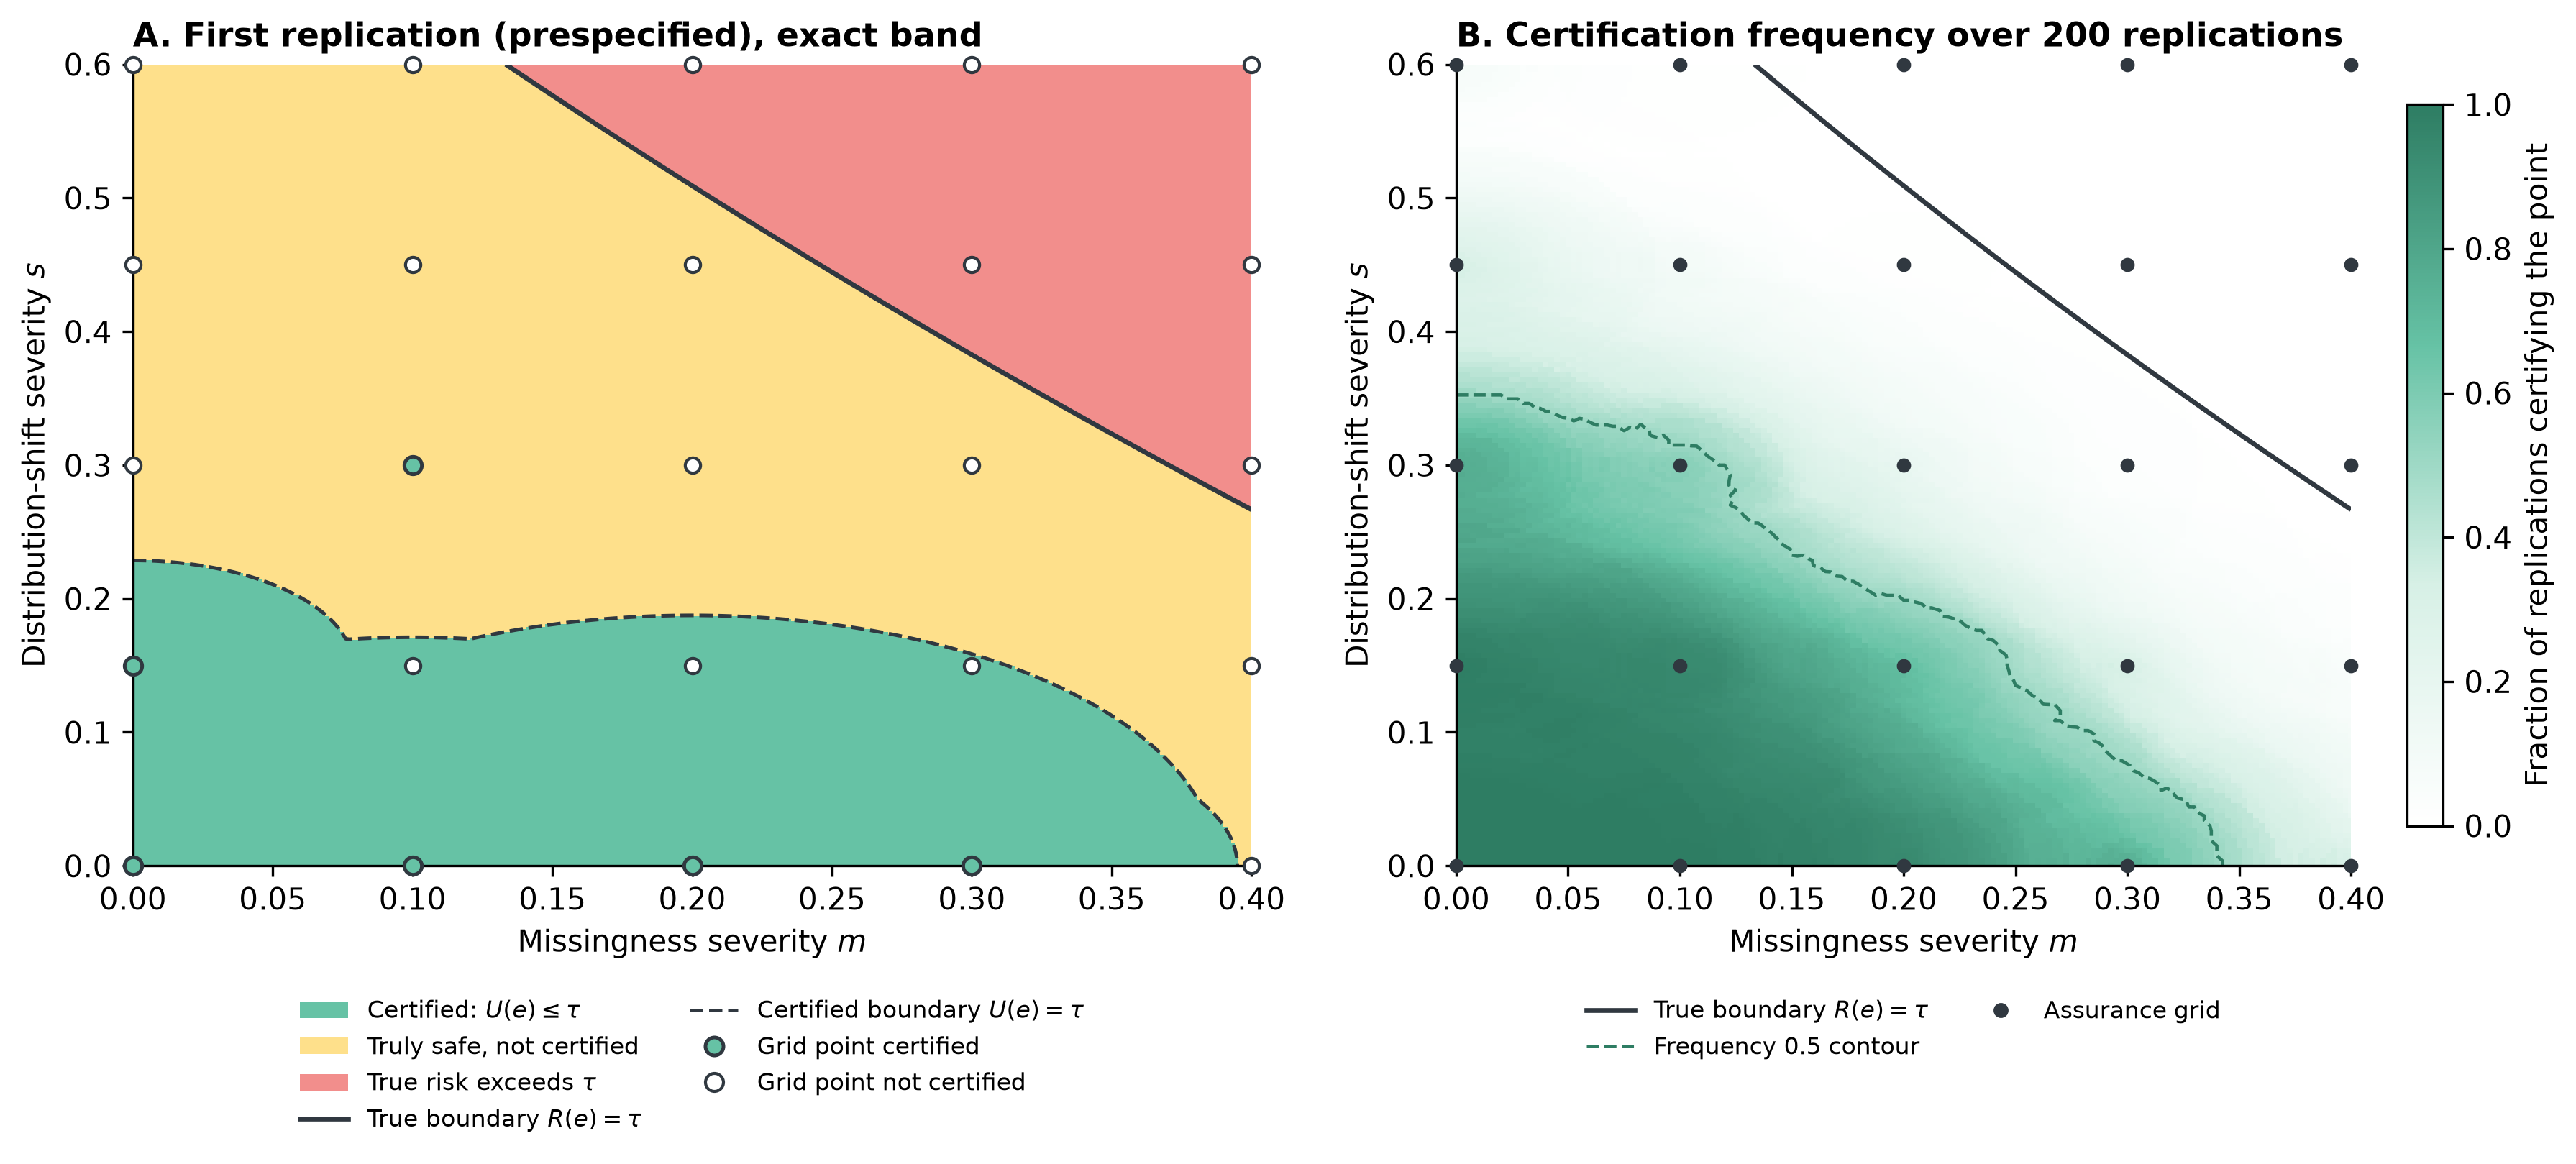

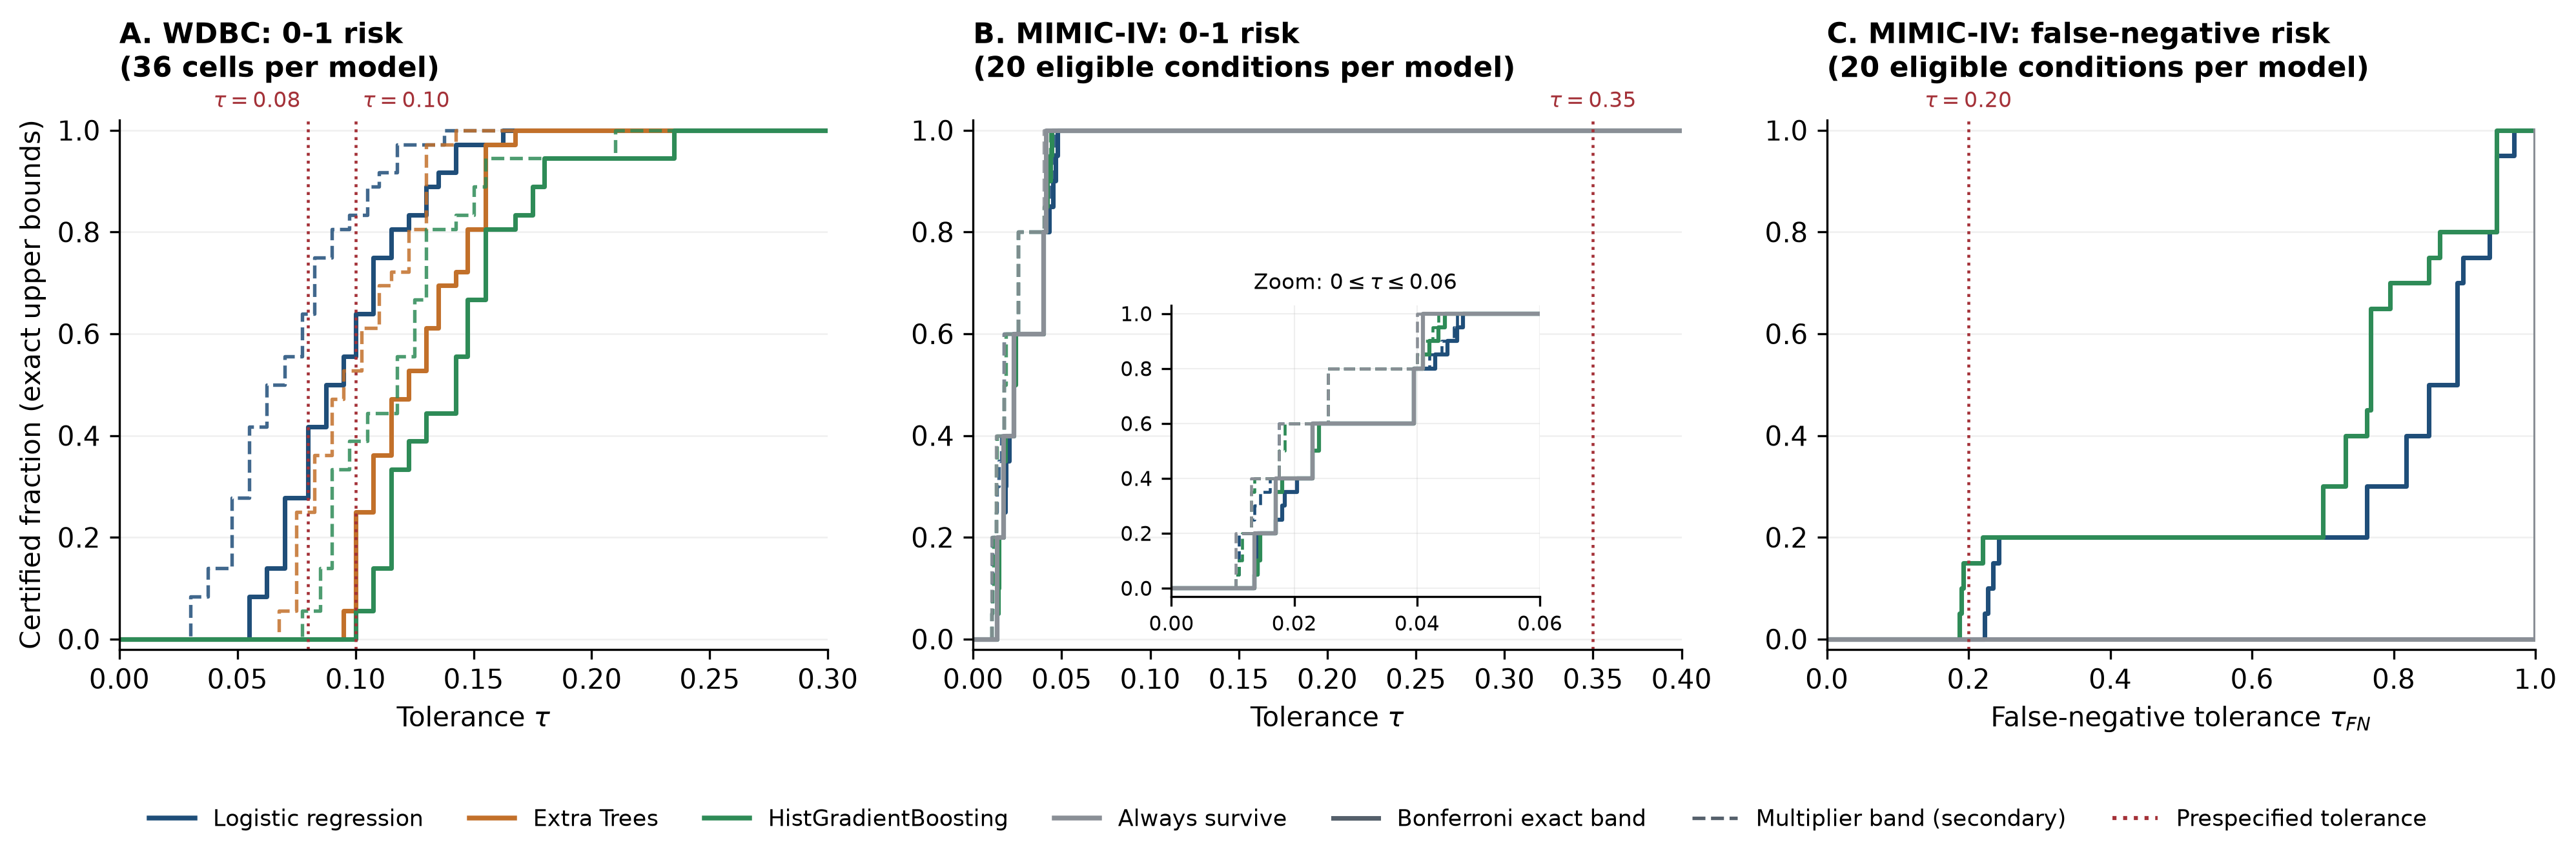

,TemporalDomain,n,deaths,eligible,zero_fn_upper,best_lower_sensitivity,certifiable_even_with_zero_fn,LR_exact_certified,HGB_exact_certified
0,2017 - 2021,2312,14,True,0.405,0.595,False,0,0
1,2018 - 2022,1645,12,True,0.454,0.546,False,0,0
2,2019 - 2022,29419,1092,True,0.007,0.993,True,0,3
3,2020 - 2022,1282,13,True,0.428,0.572,False,0,0
4,2021 - 2022,424,5,True,0.766,0.234,False,0,0
5,2022 - 2022,32,1,False,0.999,0.001,False,0,0


Minimum deaths for any certificate at tau_FN=.20 (K=72): 33; zero-FN upper bound with 14 deaths: 0.405


,true_sensitivity,target_probability,K,alpha,tau_fn,deaths_first,deaths_stable
0,0.85,0.8,72,0.05,0.2,961,995
1,0.85,0.9,72,0.05,0.2,1178,1205
2,0.90,0.8,72,0.05,0.2,217,230
3,0.90,0.9,72,0.05,0.2,261,274
4,0.95,0.8,72,0.05,0.2,87,87
5,0.95,0.9,72,0.05,0.2,94,102
6,1.00,1.0,72,0.05,0.2,33,33


In [ ]:
display(Image(filename=str(REVISION_FIG / 'continuous_exact.png'), width=900))
display(Image(filename=str(REVISION_FIG / 'tolerance_profiles.png'), width=900))
ess = R['mimic_effective_sample_size']
display(ess[['TemporalDomain', 'n', 'deaths', 'eligible', 'zero_fn_upper', 'best_lower_sensitivity',
             'certifiable_even_with_zero_fn', 'LR_exact_certified', 'HGB_exact_certified']].round(3))
need = minimal_n_zero_errors(.20, .05, 72)
print(f'Minimum deaths for any certificate at tau_FN=.20 (K=72): {need}; '
      f'zero-FN upper bound with 14 deaths: {zero_error_upper(14, .05, 72):.3f}')
display(R['mimic_deaths_needed'])

### 13.4 Local MIMIC-IV operating characteristics (credentialed data only)
Sensitivity alone does not describe the cost of a threshold. The function below refits the same
prespecified models with the same seed, recomputes the frozen class-sensitive thresholds, and writes
deployment specificity, alerts per 1,000 admissions, and PPV for every condition. It refuses to
write anything unless it reproduces the archived positive and false-negative counts for all 72
conditions. These summaries are descriptive and carry no simultaneous guarantee. After a successful
local run, the export cell writes `manuscript/generated/mimic_operating.tex`, which replaces the
author note in the manuscript. Only the aggregate CSV should be shared.

In [ ]:
if RUN_MIMIC:
    from sciguard.revision import mimic_class_sensitive_operating
    operating = mimic_class_sensitive_operating(MIMIC_ROOT, MIMIC_CONFIG, ROOT / 'results/mimic_local')
    display(operating[operating.Missingness == 0][['TemporalDomain', 'Model', 'n', 'deaths', 'sensitivity',
                                                  'specificity', 'alerts_per_1000', 'PPV']].round(3))
else:
    print('RUN_MIMIC is False: the operating-characteristics table needs credentialed MIMIC-IV data.\n'
          'Set SCIGUARD_RUN_MIMIC=1 and MIMIC_IV_PATH, restart the kernel, and run this section again.')

RUN_MIMIC is False: the operating-characteristics table needs credentialed MIMIC-IV data.
Set SCIGUARD_RUN_MIMIC=1 and MIMIC_IV_PATH, restart the kernel, and run this section again.


In [ ]:
completed = subprocess.run([sys.executable, str(ROOT / 'scripts/export_manuscript.py')],
                           cwd=ROOT, text=True, capture_output=True, check=True)
print(completed.stdout.strip())
print('MIMIC operating table present:', (ROOT / 'manuscript/generated/mimic_operating.tex').is_file())

Exported 19 manuscript inputs and 123 macros
MIMIC operating table present: False


## 14. Source and revision map
- Main theory and exact/asymptotic bounds: `src/sciguard/core.py`, `groups.py`, `baselines.py`.
- Corrected DGP and MAR/MNAR mechanisms: `simulation.py`.
- All study definitions and seeds: `experiments.py`.
- Clinical cohort, interval alignment, and aggregate exports: `mimic.py`.
- Figures: `plotting.py`; manuscript tables: `scripts/export_manuscript.py`.
- Results-revision analyses: `src/sciguard/revision.py` (runner `scripts/run_revision.py`),
  revision figures: `src/sciguard/presentation.py`, tests: `tests/test_revision.py`.
- Change log, supervisor-facing summary, and local MIMIC instructions: `docs/RESULTS_REVISION_NOTES.md`.
- Full theoretical argument and interpretation: `manuscript/main_jmlr.tex` / PDF.
- Point-by-point reviewer response and remaining evidence gaps: `docs/REVISION_RESPONSE.md`.

Primary methodological references include CCK (2013, Gaussian multiplier approximation),
Hoeffding (1963), Clopper-Pearson (1934), Holm (1979), Learn then Test (Angelopoulos et al.,
2025), and ATC (Garg et al., 2022). Bibliographic details and verified links appear in the
manuscript and `docs/SOURCE_NOTES.md`.